# Drought Forecast Verification — Template Notebook

This notebook demonstrates the full `drought-forecast-eval` workflow:

1. **Download** (optional) fresh data from BGDI
2. **Load** forecast archive and observation archive
3. **Align** observations to the forecast grid
4. **Build** a reference forecast (climatology or persistence)
5. **Compute** verification scores
6. **Visualise** skill curves and regional maps
7. **Export** results (NetCDF, CSV, HTML report)

Copy this notebook and adapt the paths / settings for your specific experiment.

---
**Docs:** `docs/` | **Source:** `drought_forecast_eval/` | **Issues / MRs:** GitLab repo

In [1]:
%load_ext autoreload
%autoreload 2

In [10]:
from pathlib import Path

# ── EDIT THESE PATHS ──────────────────────────────────────────────────────
DATA_DIR     = Path("data")                          # root data dir

ARCHIVE_DIR   = DATA_DIR / "zipfiles"               # flat dir of daily ZIPs
HISTORIC_ZIP  = DATA_DIR / "historic.csv.zip"      # full observation archive
NC_DIR = DATA_DIR / "netcdf"                            # netCDF dir
SHAPEFILE     = Path('shapefiles/BAFU_Grossregionen_v3.shp')
OUTPUT_DIR    = Path("output")

DATE_RANGE    = ("2025-04-01", "2026-07-15")        # verification window
REGIONS       = "all"                                # or e.g. [1, 5, 12, 31]
VARIABLES     = "all"                                # or e.g. ["spi_1m", "cdi"]
CDI_THRESHOLD = 2                                    # CDI ≥ threshold = drought event
# ──────────────────────────────────────────────────────────────────────────

In [13]:
! mkdir -p {NC_DIR}

## 1. (Optional) Download fresh data from BGDI

In [4]:
from drought_forecast_eval.io.downloader import download_archive, download_historic

# Uncomment to download:
# download_archive(ARCHIVE_DIR, start=DATE_RANGE[0], end=DATE_RANGE[1])
download_historic(HISTORIC_ZIP)


PosixPath('data/historic.csv.zip')

## 2. Load data

In [15]:
from drought_forecast_eval.io.loader import load_forecasts, load_observations_combined
import xarray as xr

RECREATE_NETCDF = False  # set to True to re-create netCDF files from raw data

if RECREATE_NETCDF:
    ds_fcst = load_forecasts(ARCHIVE_DIR, date_range=DATE_RANGE)
    ds_obs  = load_observations_combined(HISTORIC_ZIP, archive_dir=ARCHIVE_DIR)
    ds_fcst.to_netcdf(NC_DIR / "forecasts.nc")
    ds_obs.to_netcdf(NC_DIR / "observations.nc")
else:
    ds_fcst = xr.open_dataset(NC_DIR / "forecasts.nc")
    ds_obs  = xr.open_dataset(NC_DIR / "observations.nc")


In [16]:
ds_fcst

<xarray.Dataset> Size: 18MB
Dimensions:                  (forecast_reference_time: 376,
                              drought_region_id: 38, lead_week: 4)
Coordinates:
  * forecast_reference_time  (forecast_reference_time) datetime64[ns] 3kB 202...
  * drought_region_id        (drought_region_id) int64 304B 31 32 33 ... 67 68
  * lead_week                (lead_week) int64 32B 0 1 2 3
    valid_at                 (forecast_reference_time, drought_region_id, lead_week) datetime64[ns] 457kB ...
Data variables: (12/39)
    cdi_p50                  (forecast_reference_time, drought_region_id, lead_week) float64 457kB ...
    precip_1m_index_p50      (forecast_reference_time, drought_region_id, lead_week) float64 457kB ...
    precip_3m_index_p50      (forecast_reference_time, drought_region_id, lead_week) float64 457kB ...
    precip_24m_index_p50     (forecast_reference_time, drought_region_id, lead_week) float64 457kB ...
    hydro_index_p50          (forecast_reference_time, drought_region_id, lead_week) float64 457kB ...
    soil_moisture_index_p50  (forecast_reference_time, drought_region_id, lead_week) float64 457kB ...
    ...                       ...
    spi_24m_p10              (forecast_reference_time, drought_region_id, lead_week) float64 457kB ...
    spi_24m_p50              (forecast_reference_time, drought_region_id, lead_week) float64 457kB ...
    spi_24m_p90              (forecast_reference_time, drought_region_id, lead_week) float64 457kB ...
    soil_moisture_ufc_p10    (forecast_reference_time, drought_region_id, lead_week) float64 457kB ...
    soil_moisture_ufc_p50    (forecast_reference_time, drought_region_id, lead_week) float64 457kB ...
    soil_moisture_ufc_p90    (forecast_reference_time, drought_region_id, lead_week) float64 457kB ...
Attributes:
    source:       drought_forecast_eval
    description:  Swiss drought forecast archive

In [17]:
ds_obs

<xarray.Dataset> Size: 10MB
Dimensions:              (drought_region_id: 38, valid_at: 1859)
Coordinates:
  * drought_region_id    (drought_region_id) int64 304B 31 32 33 34 ... 66 67 68
  * valid_at             (valid_at) datetime64[ns] 15kB 1990-12-31 ... 2026-0...
Data variables: (12/18)
    cdi                  (drought_region_id, valid_at) float64 565kB ...
    precip_1m_index      (drought_region_id, valid_at) float64 565kB ...
    precip_3m_index      (drought_region_id, valid_at) float64 565kB ...
    precip_24m_index     (drought_region_id, valid_at) float64 565kB ...
    hydro_index          (drought_region_id, valid_at) float64 565kB ...
    soil_moisture_index  (drought_region_id, valid_at) float64 565kB ...
    ...                   ...
    spi_3m               (drought_region_id, valid_at) float64 565kB ...
    spi_6m               (drought_region_id, valid_at) float64 565kB ...
    spi_12m              (drought_region_id, valid_at) float64 565kB ...
    spi_24m              (drought_region_id, valid_at) float64 565kB ...
    soil_moisture_ufc    (drought_region_id, valid_at) float64 565kB ...
    vhi                  (drought_region_id, valid_at) float64 565kB ...
Attributes:
    source:       drought_forecast_eval
    description:  Swiss drought observation archive (historic + current)

<xarray.Dataset> Size: 10MB
Dimensions:              (drought_region_id: 38, valid_at: 1859)
Coordinates:
  * drought_region_id    (drought_region_id) int64 304B 31 32 33 34 ... 66 67 68
  * valid_at             (valid_at) datetime64[ns] 15kB 1990-12-31 ... 2026-0...
Data variables: (12/18)
    cdi                  (drought_region_id, valid_at) float64 565kB 1.0 ... nan
    precip_1m_index      (drought_region_id, valid_at) float64 565kB 1.0 ... nan
    precip_3m_index      (drought_region_id, valid_at) float64 565kB 1.0 ... nan
    precip_24m_index     (drought_region_id, valid_at) float64 565kB 1.0 ... nan
    hydro_index          (drought_region_id, valid_at) float64 565kB 1.0 ... nan
    soil_moisture_index  (drought_region_id, valid_at) float64 565kB nan ... nan
    ...                   ...
    spi_3m               (drought_region_id, valid_at) float64 565kB 0.77 ......
    spi_6m               (drought_region_id, valid_at) float64 565kB 0.4 ... nan
    spi_12m              (drought_region_id, valid_at) float64 565kB 0.82 ......
    spi_24m              (drought_region_id, valid_at) float64 565kB -0.47 .....
    soil_moisture_ufc    (drought_region_id, valid_at) float64 565kB nan ... nan
    vhi                  (drought_region_id, valid_at) float64 565kB nan ... nan
Attributes:
    source:       drought_forecast_eval
    description:  Swiss drought observation archive (historic + current)

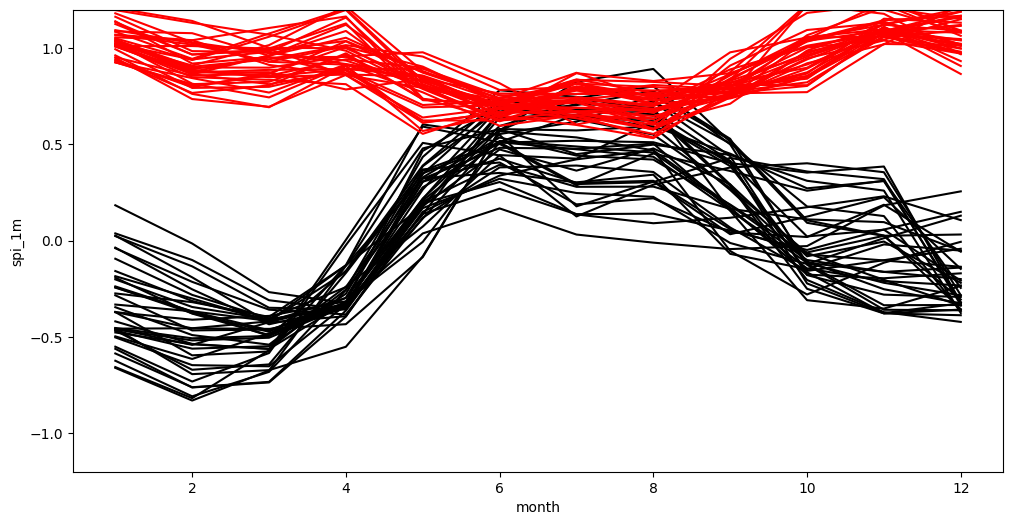

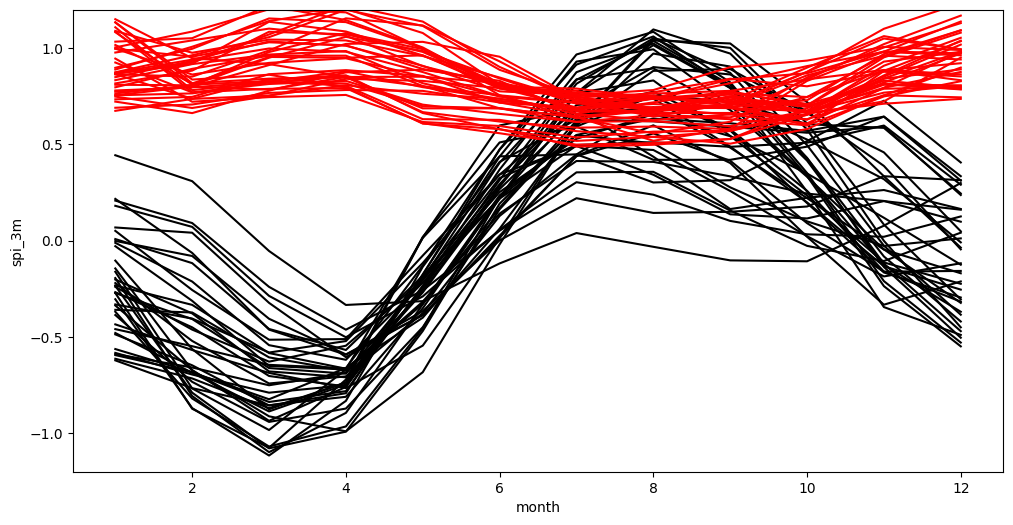

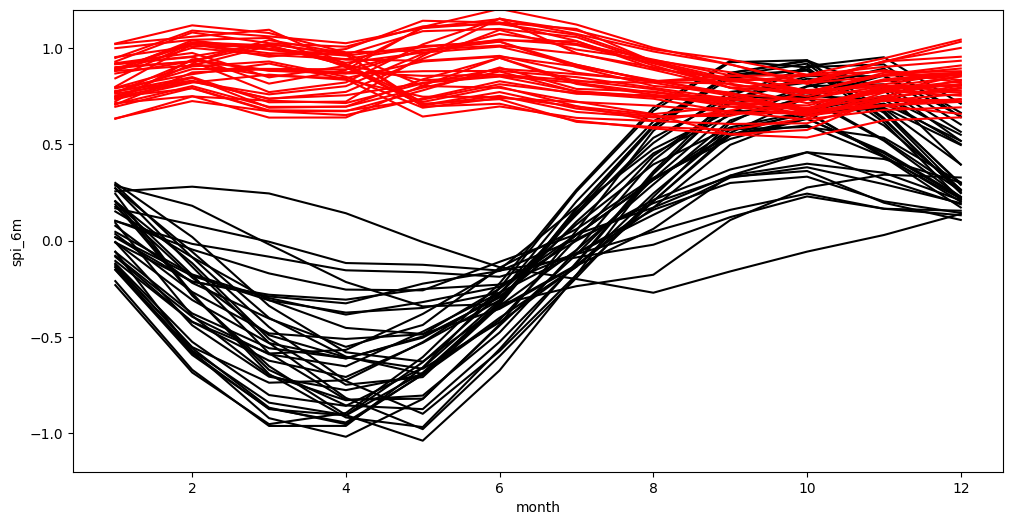

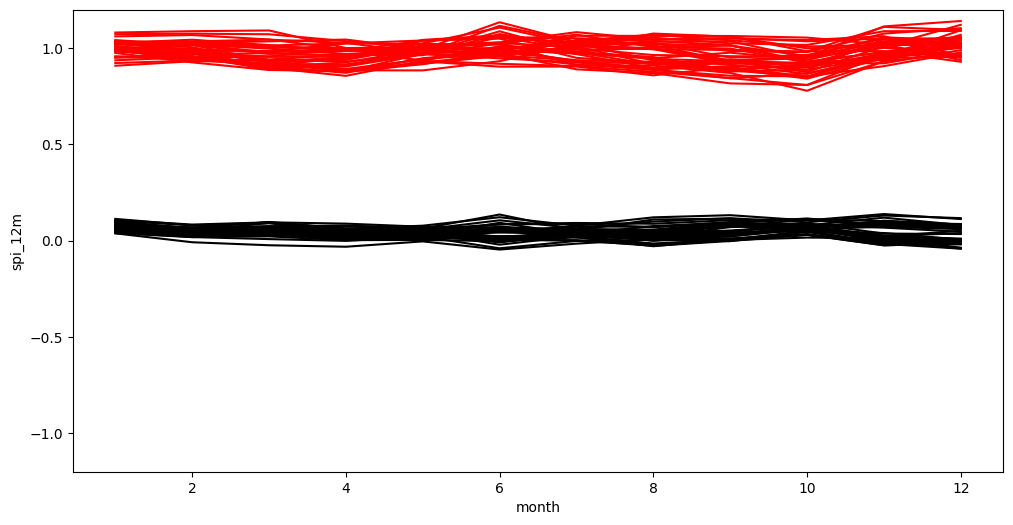

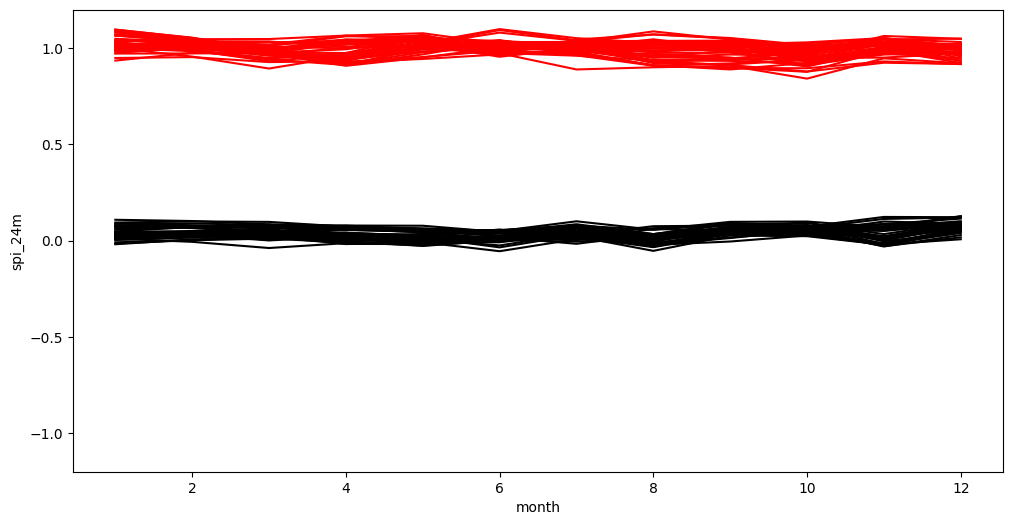

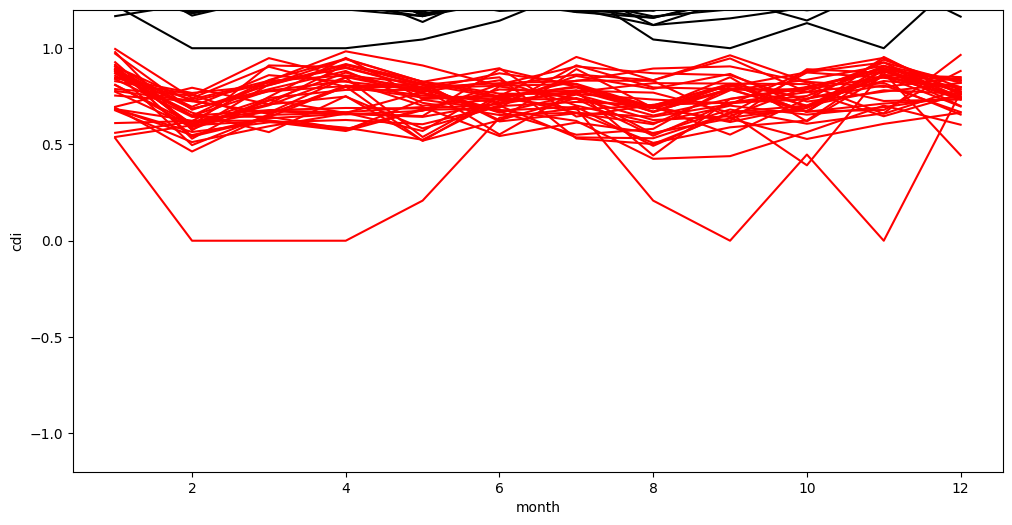

In [68]:
ds_obs_ref_period = ds_obs.sel(valid_at=slice("1991-01-01", "2020-12-31"))

for var in ["spi_1m", "spi_3m", "spi_6m", "spi_12m", "spi_24m", "cdi"]:
    f,ax=plt.subplots(figsize=(12,6))
    obs_monthly_mean = ds_obs_ref_period.groupby("valid_at.month").mean()[var].plot(hue="drought_region_id", color="black", add_legend=False,ylim=(-1.2,1.2))
    obs_monthly_std = ds_obs_ref_period.groupby("valid_at.month").std()[var].plot(hue="drought_region_id", color="red", add_legend=False,ylim=(-1.2,1.2))

## 3. Align observations to the forecast grid

In [21]:
from drought_forecast_eval import align_obs_to_forecast

if RECREATE_NETCDF:
    ds_merged = align_obs_to_forecast(ds_fcst, ds_obs)
    print("Merged dataset dims:", dict(ds_merged.dims))
    ds_merged.to_netcdf(NC_DIR / "merged.nc")
else:
    ds_merged = xr.open_dataset(NC_DIR / "merged.nc")

In [22]:
ds_merged

<xarray.Dataset> Size: 27MB
Dimensions:                  (forecast_reference_time: 376,
                              drought_region_id: 38, lead_week: 4)
Coordinates:
  * forecast_reference_time  (forecast_reference_time) datetime64[ns] 3kB 202...
  * drought_region_id        (drought_region_id) int64 304B 31 32 33 ... 67 68
  * lead_week                (lead_week) int64 32B 0 1 2 3
    valid_at                 (forecast_reference_time, drought_region_id, lead_week) datetime64[ns] 457kB ...
Data variables: (12/57)
    cdi_p50                  (forecast_reference_time, drought_region_id, lead_week) float64 457kB ...
    precip_1m_index_p50      (forecast_reference_time, drought_region_id, lead_week) float64 457kB ...
    precip_3m_index_p50      (forecast_reference_time, drought_region_id, lead_week) float64 457kB ...
    precip_24m_index_p50     (forecast_reference_time, drought_region_id, lead_week) float64 457kB ...
    hydro_index_p50          (forecast_reference_time, drought_region_id, lead_week) float64 457kB ...
    soil_moisture_index_p50  (forecast_reference_time, drought_region_id, lead_week) float64 457kB ...
    ...                       ...
    spi_3m_obs               (forecast_reference_time, drought_region_id, lead_week) float64 457kB ...
    spi_6m_obs               (forecast_reference_time, drought_region_id, lead_week) float64 457kB ...
    spi_12m_obs              (forecast_reference_time, drought_region_id, lead_week) float64 457kB ...
    spi_24m_obs              (forecast_reference_time, drought_region_id, lead_week) float64 457kB ...
    soil_moisture_ufc_obs    (forecast_reference_time, drought_region_id, lead_week) float64 457kB ...
    vhi_obs                  (forecast_reference_time, drought_region_id, lead_week) float64 457kB ...
Attributes:
    source:       drought_forecast_eval
    description:  Swiss drought forecast archive

In [23]:
mask = ds_merged["forecast_reference_time"].dt.weekday == 0
ds_mondays = ds_merged.isel(forecast_reference_time=mask.values)

In [24]:
ds_mondays

<xarray.Dataset> Size: 4MB
Dimensions:                  (forecast_reference_time: 53,
                              drought_region_id: 38, lead_week: 4)
Coordinates:
  * forecast_reference_time  (forecast_reference_time) datetime64[ns] 424B 20...
  * drought_region_id        (drought_region_id) int64 304B 31 32 33 ... 67 68
  * lead_week                (lead_week) int64 32B 0 1 2 3
    valid_at                 (forecast_reference_time, drought_region_id, lead_week) datetime64[ns] 64kB ...
Data variables: (12/57)
    cdi_p50                  (forecast_reference_time, drought_region_id, lead_week) float64 64kB ...
    precip_1m_index_p50      (forecast_reference_time, drought_region_id, lead_week) float64 64kB ...
    precip_3m_index_p50      (forecast_reference_time, drought_region_id, lead_week) float64 64kB ...
    precip_24m_index_p50     (forecast_reference_time, drought_region_id, lead_week) float64 64kB ...
    hydro_index_p50          (forecast_reference_time, drought_region_id, lead_week) float64 64kB ...
    soil_moisture_index_p50  (forecast_reference_time, drought_region_id, lead_week) float64 64kB ...
    ...                       ...
    spi_3m_obs               (forecast_reference_time, drought_region_id, lead_week) float64 64kB ...
    spi_6m_obs               (forecast_reference_time, drought_region_id, lead_week) float64 64kB ...
    spi_12m_obs              (forecast_reference_time, drought_region_id, lead_week) float64 64kB ...
    spi_24m_obs              (forecast_reference_time, drought_region_id, lead_week) float64 64kB ...
    soil_moisture_ufc_obs    (forecast_reference_time, drought_region_id, lead_week) float64 64kB ...
    vhi_obs                  (forecast_reference_time, drought_region_id, lead_week) float64 64kB ...
Attributes:
    source:       drought_forecast_eval
    description:  Swiss drought forecast archive

## 4. Build reference forecast

Choose `"climatology"`, `"persistence"`, or `"both

In [26]:
from drought_forecast_eval import climatology_reference, persistence_reference

if RECREATE_NETCDF:
    ds_ref_clim = climatology_reference(ds_obs, ds_fcst, week_window=4)
    ds_ref_pers = persistence_reference(ds_obs, ds_fcst)
    ds_ref_clim.to_netcdf(NC_DIR / "climatology_reference.nc")
    ds_ref_pers.to_netcdf(NC_DIR / "persistence_reference.nc")
else:
    ds_ref_clim = xr.open_dataset(NC_DIR / "climatology_reference.nc")
    ds_ref_pers = xr.open_dataset(NC_DIR / "persistence_reference.nc")


print("Climatology reference variables:", list(ds_ref_clim.data_vars)[:5], "...")

Climatology reference variables: ['cdi_ref_p10', 'cdi_ref_p50', 'cdi_ref_p90', 'precip_1m_index_ref_p10', 'precip_1m_index_ref_p50'] ...


## 5 Explorative Data Analysis

In [27]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [28]:
import matplotlib.pylab as plt

%matplotlib inline
plt.show()

In [29]:
RID = 1 # Region Identifier

In [30]:
from drought_forecast_eval.visualization.skill_curves import plot_forecast_plume

In [39]:
ds_ref_clim

<xarray.Dataset> Size: 25MB
Dimensions:                      (forecast_reference_time: 376,
                                  drought_region_id: 38, lead_week: 4)
Coordinates:
  * forecast_reference_time      (forecast_reference_time) datetime64[ns] 3kB ...
  * drought_region_id            (drought_region_id) int64 304B 31 32 ... 67 68
  * lead_week                    (lead_week) int64 32B 0 1 2 3
Data variables: (12/54)
    cdi_ref_p10                  (forecast_reference_time, drought_region_id, lead_week) float64 457kB ...
    cdi_ref_p50                  (forecast_reference_time, drought_region_id, lead_week) float64 457kB ...
    cdi_ref_p90                  (forecast_reference_time, drought_region_id, lead_week) float64 457kB ...
    precip_1m_index_ref_p10      (forecast_reference_time, drought_region_id, lead_week) float64 457kB ...
    precip_1m_index_ref_p50      (forecast_reference_time, drought_region_id, lead_week) float64 457kB ...
    precip_1m_index_ref_p90      (forecast_reference_time, drought_region_id, lead_week) float64 457kB ...
    ...                           ...
    soil_moisture_ufc_ref_p10    (forecast_reference_time, drought_region_id, lead_week) float64 457kB ...
    soil_moisture_ufc_ref_p50    (forecast_reference_time, drought_region_id, lead_week) float64 457kB ...
    soil_moisture_ufc_ref_p90    (forecast_reference_time, drought_region_id, lead_week) float64 457kB ...
    vhi_ref_p10                  (forecast_reference_time, drought_region_id, lead_week) float64 457kB ...
    vhi_ref_p50                  (forecast_reference_time, drought_region_id, lead_week) float64 457kB ...
    vhi_ref_p90                  (forecast_reference_time, drought_region_id, lead_week) float64 457kB ...
Attributes:
    reference_type:  climatology
    week_window:     4

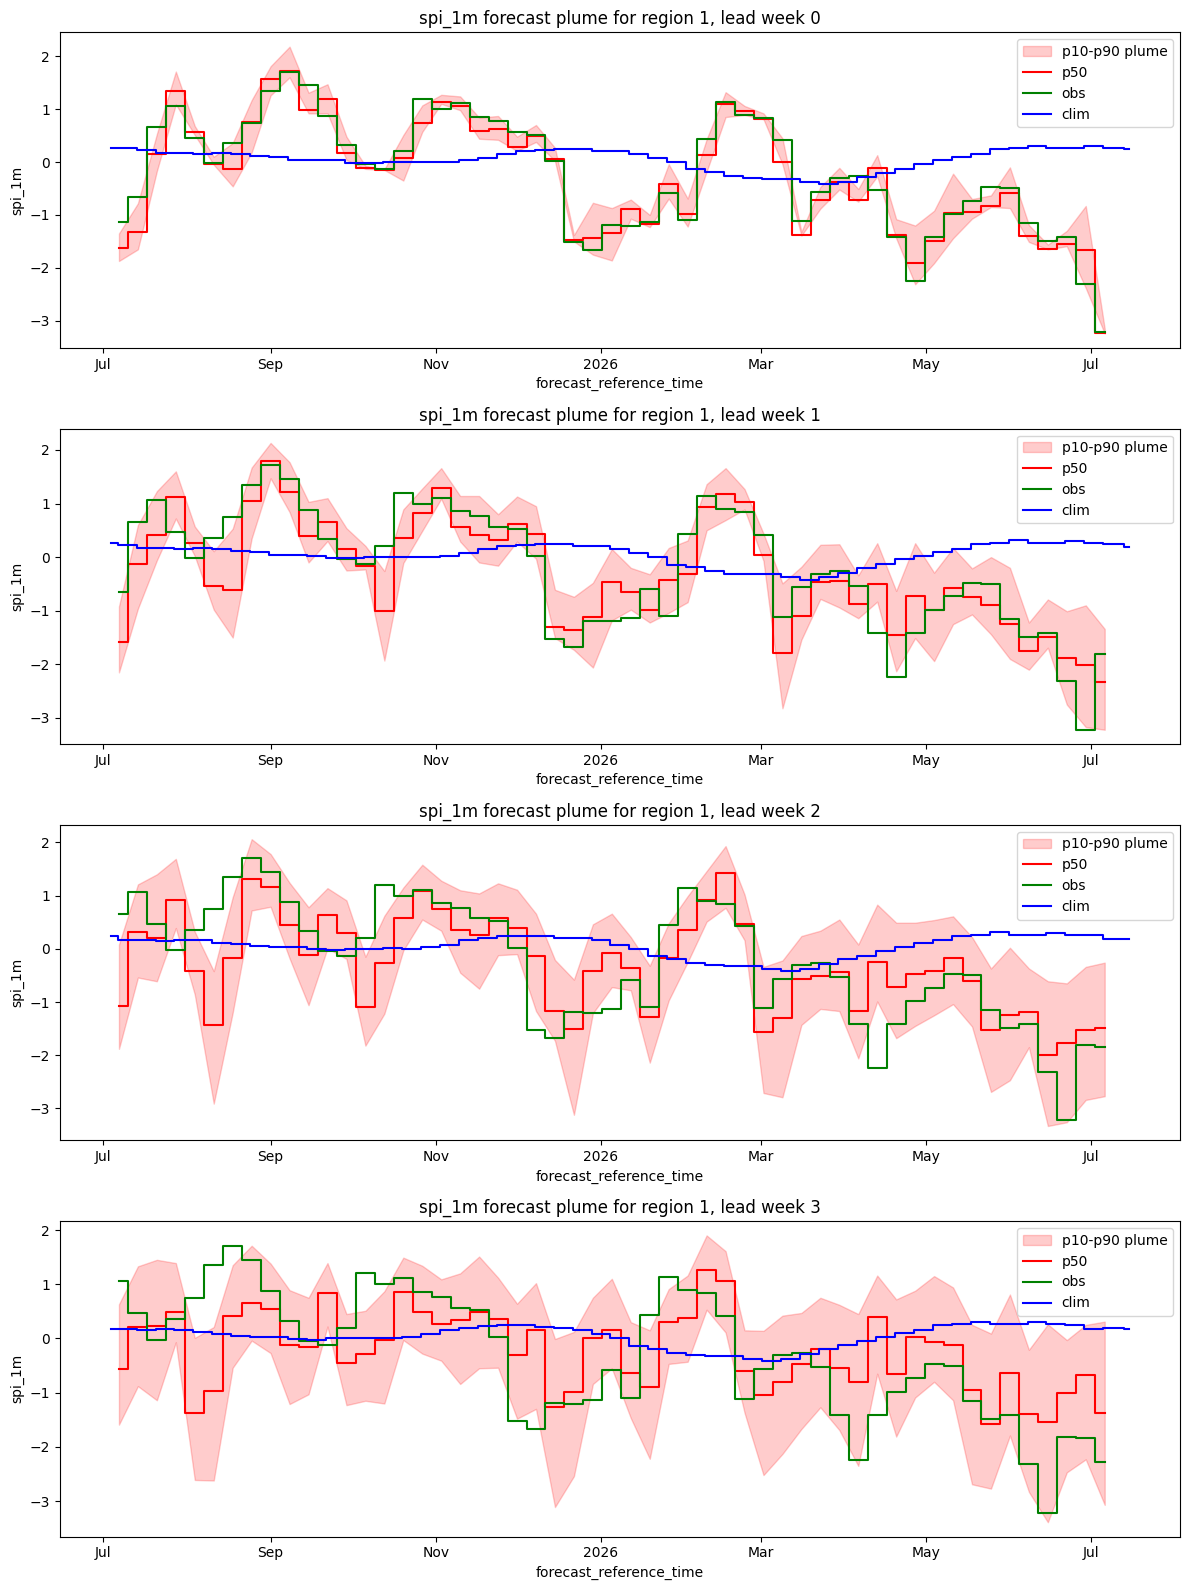

In [40]:
fig, ax = plot_forecast_plume(ds_merged=ds_mondays,
                    ds_ref_clim=ds_ref_clim,
                    ds_ref_pers=ds_ref_pers,
                    rid=RID,
                    var="spi_1m",
                    time_dim="forecast_reference_time")


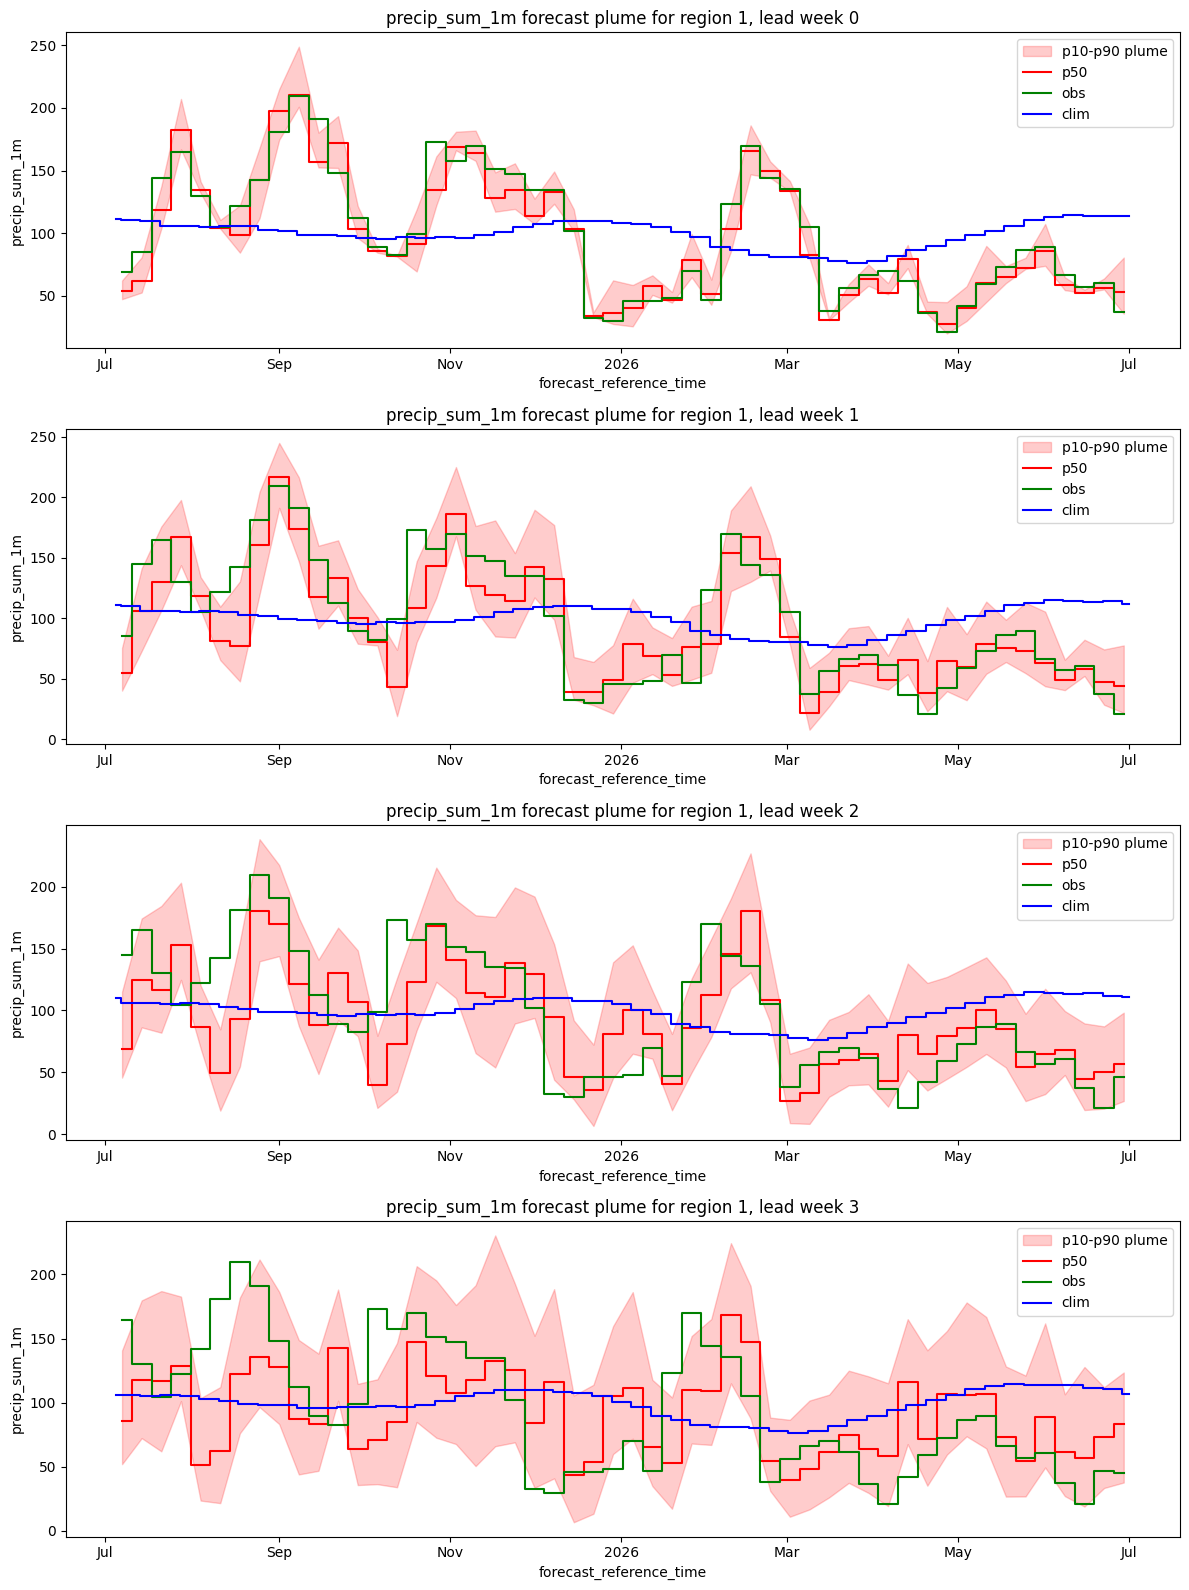

In [ ]:
fig, ax = plot_forecast_plume(ds_merged=ds_mondays,
                    ds_ref_clim=ds_ref_clim,
                    ds_ref_pers=ds_ref_pers,
                    rid=RID,
                    var="precip_sum_1m")

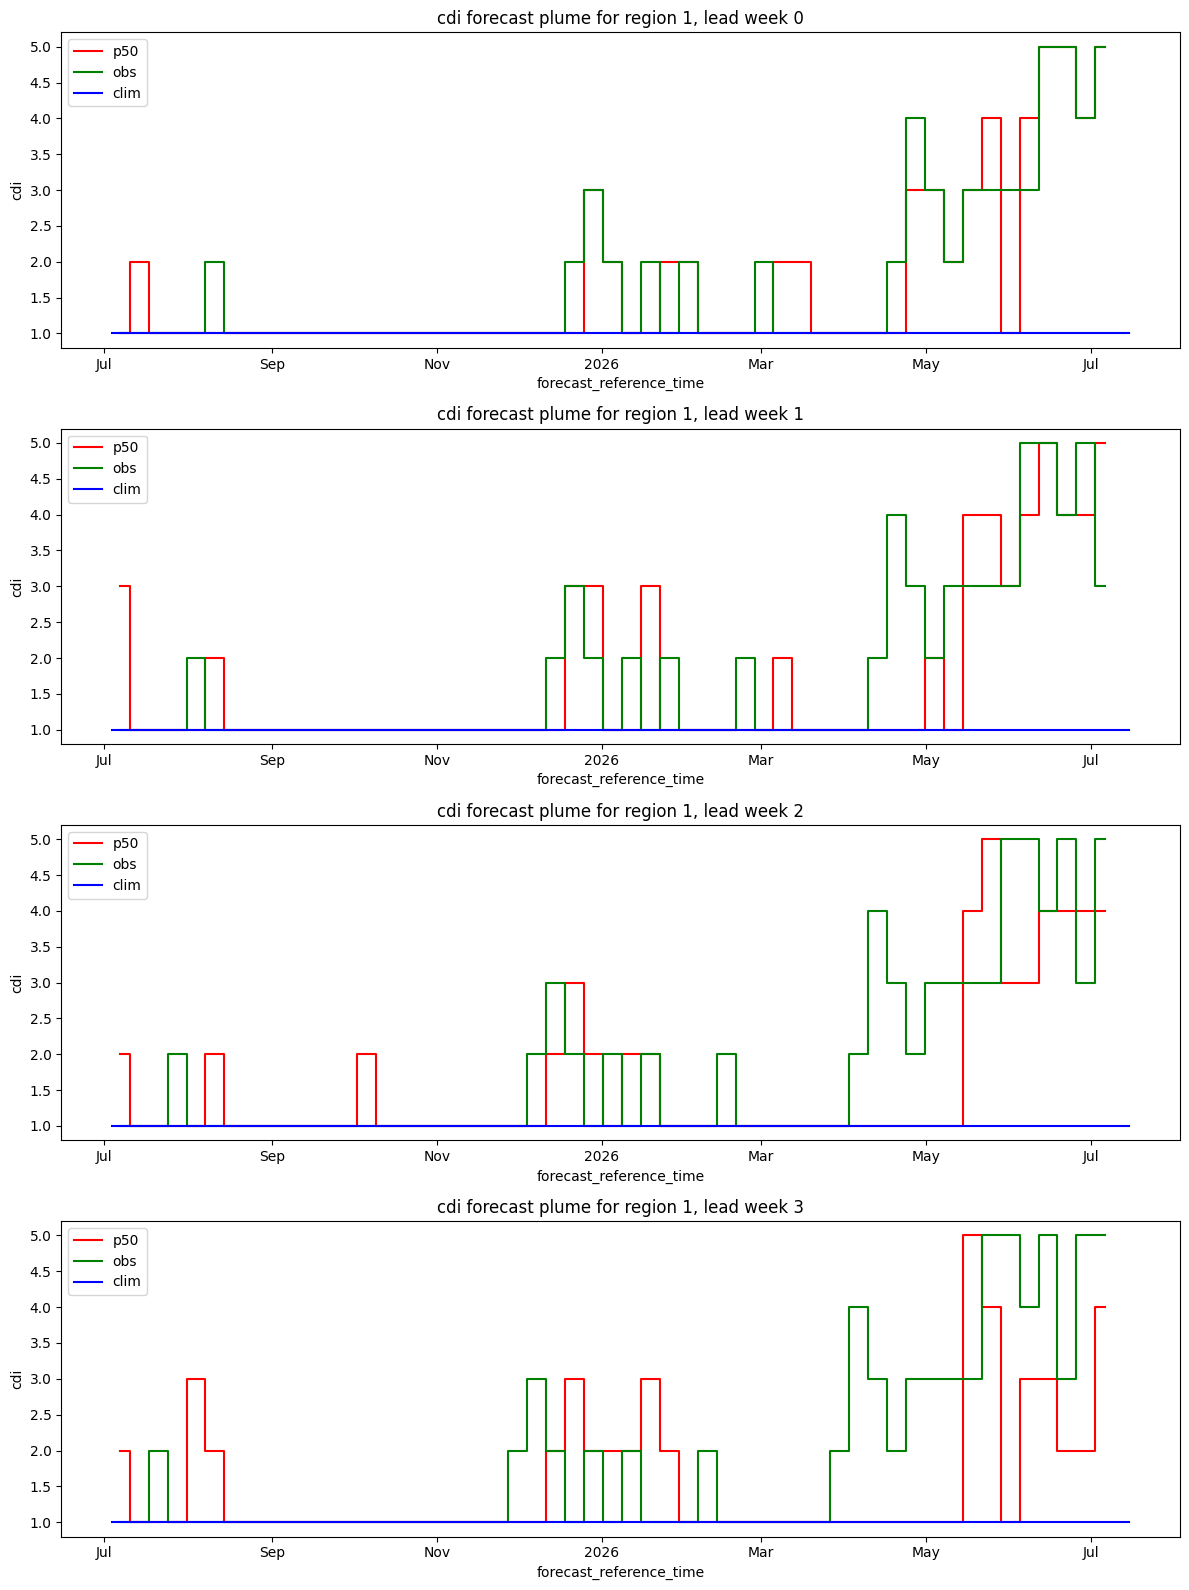

In [50]:
fig, ax = plot_forecast_plume(ds_merged=ds_mondays,
                    ds_ref_clim=ds_ref_clim,
                    ds_ref_pers=ds_ref_pers,
                    rid=RID,
                    var="cdi")

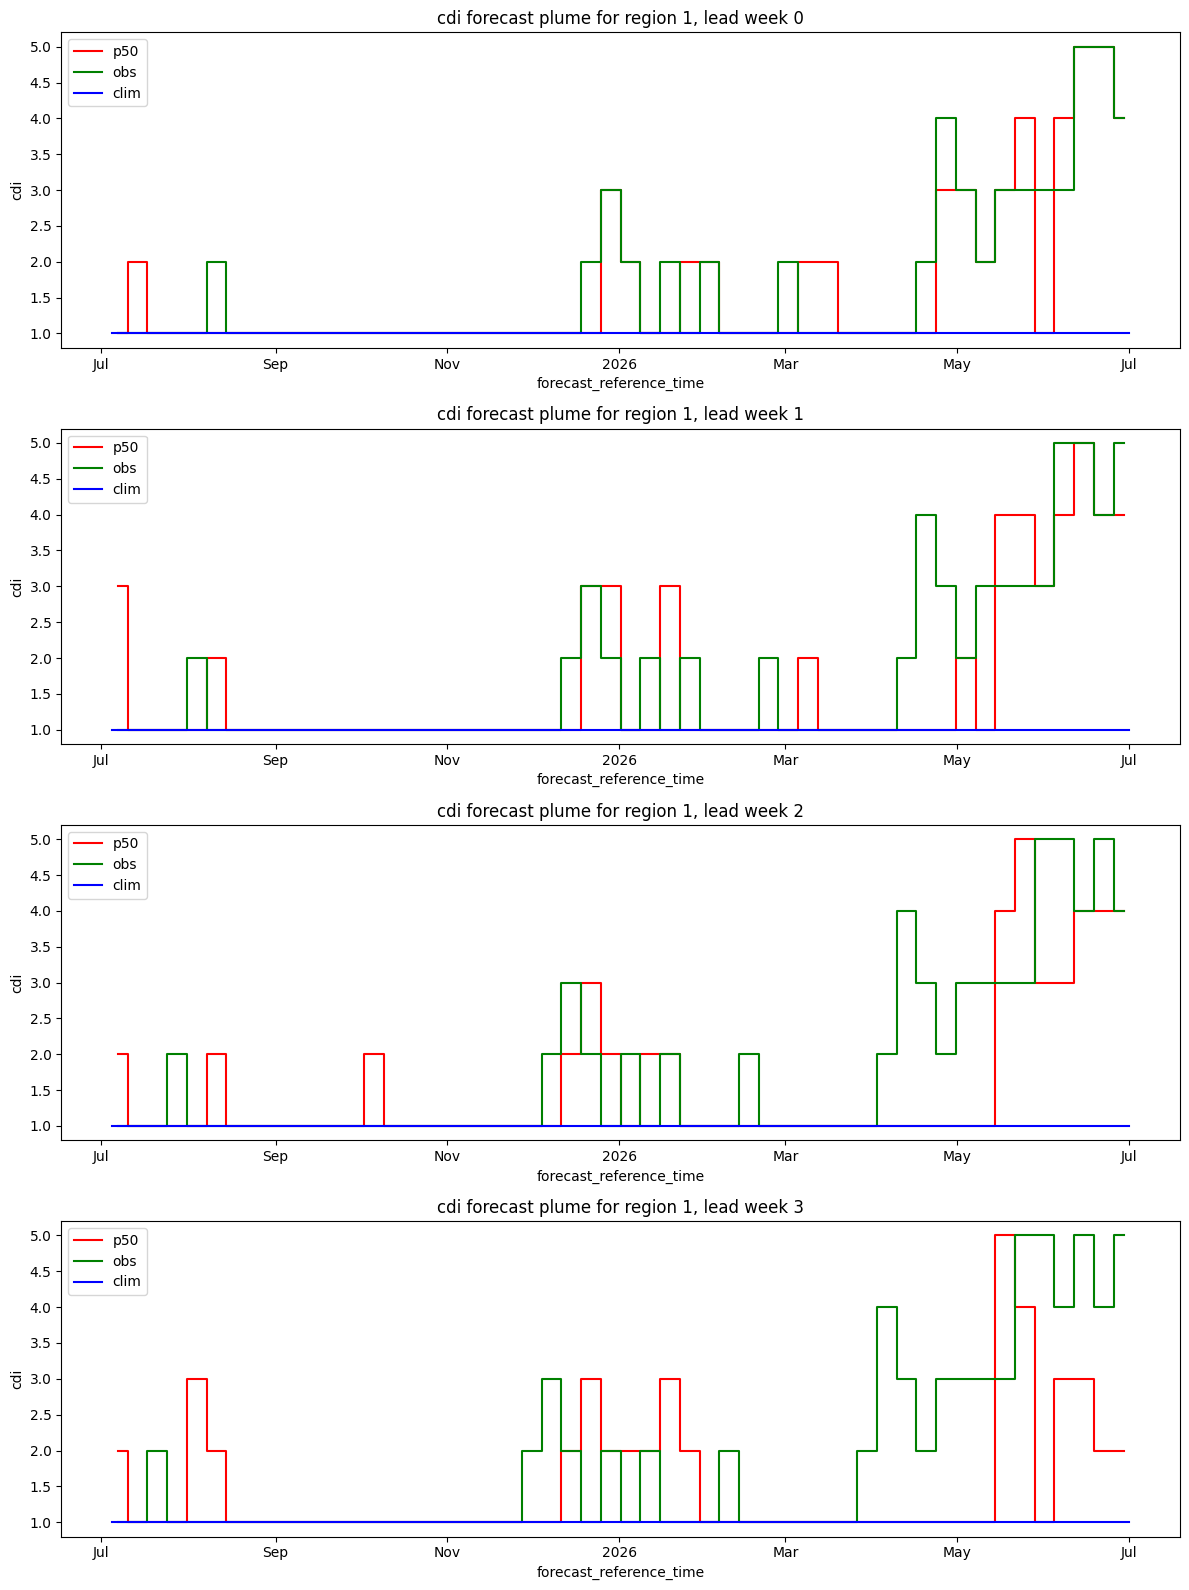

In [ ]:
fig, ax = plot_forecast_plume(ds_merged=ds_mondays,
                    ds_ref_clim=ds_ref_clim,
                    ds_ref_pers=ds_ref_pers,
                    rid=1,
                    var="cdi")

## 6. Compute scores

In [52]:
mask

<xarray.DataArray 'forecast_reference_time' (forecast_reference_time: 53)> Size: 53B
array([False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True])
Coordinates:
  * forecast_reference_time  (forecast_reference_time) datetime64[ns] 424B 20...

In [53]:
from drought_forecast_eval import compute_scores
import numpy as np

frt = ds_mondays["forecast_reference_time"]
mask = (
    ((frt >= np.datetime64("2026-03-01")) & (frt <= np.datetime64("2026-09-01")))
)
ds_sel = ds_mondays.isel(forecast_reference_time=mask.values)

ds_scores = compute_scores(
    ds_sel,
    variables=VARIABLES,
    scores="default",
    ds_ref=ds_ref_clim,
    cdi_threshold=CDI_THRESHOLD,
)

print("Score variables:", list(ds_scores.data_vars))
ds_scores

Score variables: ['cdi_mae', 'cdi_rmse', 'cdi_bias', 'cdi_correlation', 'precip_1m_index_mae', 'precip_1m_index_rmse', 'precip_1m_index_bias', 'precip_1m_index_correlation', 'precip_3m_index_mae', 'precip_3m_index_rmse', 'precip_3m_index_bias', 'precip_3m_index_correlation', 'precip_24m_index_mae', 'precip_24m_index_rmse', 'precip_24m_index_bias', 'precip_24m_index_correlation', 'hydro_index_mae', 'hydro_index_rmse', 'hydro_index_bias', 'hydro_index_correlation', 'soil_moisture_index_mae', 'soil_moisture_index_rmse', 'soil_moisture_index_bias', 'soil_moisture_index_correlation', 'precip_sum_1m_mae', 'precip_sum_1m_rmse', 'precip_sum_1m_bias', 'precip_sum_1m_correlation', 'precip_sum_1m_pinball', 'precip_sum_1m_interval_score', 'precip_sum_3m_mae', 'precip_sum_3m_rmse', 'precip_sum_3m_bias', 'precip_sum_3m_correlation', 'precip_sum_3m_pinball', 'precip_sum_3m_interval_score', 'precip_sum_6m_mae', 'precip_sum_6m_rmse', 'precip_sum_6m_bias', 'precip_sum_6m_correlation', 'precip_sum_6m_pin

<xarray.Dataset> Size: 110kB
Dimensions:                           (drought_region_id: 38, lead_week: 4)
Coordinates:
  * drought_region_id                 (drought_region_id) int64 304B 31 ... 68
  * lead_week                         (lead_week) int64 32B 0 1 2 3
Data variables: (12/90)
    cdi_mae                           (drought_region_id, lead_week) float64 1kB ...
    cdi_rmse                          (drought_region_id, lead_week) float64 1kB ...
    cdi_bias                          (drought_region_id, lead_week) float64 1kB ...
    cdi_correlation                   (drought_region_id, lead_week) float64 1kB ...
    precip_1m_index_mae               (drought_region_id, lead_week) float64 1kB ...
    precip_1m_index_rmse              (drought_region_id, lead_week) float64 1kB ...
    ...                                ...
    soil_moisture_ufc_mae             (drought_region_id, lead_week) float64 1kB ...
    soil_moisture_ufc_rmse            (drought_region_id, lead_week) float64 1kB ...
    soil_moisture_ufc_bias            (drought_region_id, lead_week) float64 1kB ...
    soil_moisture_ufc_correlation     (drought_region_id, lead_week) float64 1kB ...
    soil_moisture_ufc_pinball         (drought_region_id, lead_week) float64 1kB ...
    soil_moisture_ufc_interval_score  (drought_region_id, lead_week) float64 1kB ...
Attributes:
    source:            drought_forecast_eval
    variables_scored:  cdi,precip_1m_index,precip_3m_index,precip_24m_index,h...
    scores_computed:   mae,rmse,bias,correlation,pinball,interval_score
    cdi_threshold:     2
    reference_type:    climatology

In [54]:
ds_scores

<xarray.Dataset> Size: 110kB
Dimensions:                           (drought_region_id: 38, lead_week: 4)
Coordinates:
  * drought_region_id                 (drought_region_id) int64 304B 31 ... 68
  * lead_week                         (lead_week) int64 32B 0 1 2 3
Data variables: (12/90)
    cdi_mae                           (drought_region_id, lead_week) float64 1kB ...
    cdi_rmse                          (drought_region_id, lead_week) float64 1kB ...
    cdi_bias                          (drought_region_id, lead_week) float64 1kB ...
    cdi_correlation                   (drought_region_id, lead_week) float64 1kB ...
    precip_1m_index_mae               (drought_region_id, lead_week) float64 1kB ...
    precip_1m_index_rmse              (drought_region_id, lead_week) float64 1kB ...
    ...                                ...
    soil_moisture_ufc_mae             (drought_region_id, lead_week) float64 1kB ...
    soil_moisture_ufc_rmse            (drought_region_id, lead_week) float64 1kB ...
    soil_moisture_ufc_bias            (drought_region_id, lead_week) float64 1kB ...
    soil_moisture_ufc_correlation     (drought_region_id, lead_week) float64 1kB ...
    soil_moisture_ufc_pinball         (drought_region_id, lead_week) float64 1kB ...
    soil_moisture_ufc_interval_score  (drought_region_id, lead_week) float64 1kB ...
Attributes:
    source:            drought_forecast_eval
    variables_scored:  cdi,precip_1m_index,precip_3m_index,precip_24m_index,h...
    scores_computed:   mae,rmse,bias,correlation,pinball,interval_score
    cdi_threshold:     2
    reference_type:    climatology

### 5a. Add custom metrics
You can register your own scoring function and include it by name:

In [ ]:
import xarray as xr
from drought_forecast_eval import register_score

def my_custom_score(fcst: xr.DataArray, obs: xr.DataArray, **kwargs) -> xr.DataArray:
    """Example: mean signed error."""
    return (fcst - obs).mean(dim=kwargs.get("reduce_dims", []))

register_score("signed_error", my_custom_score)

ds_scores_custom = compute_scores(
    ds_merged,
    variables=["spi_1m", "cdi"],
    scores=["mae", "signed_error"],
)
ds_scores_custom

<xarray.Dataset> Size: 3kB
Dimensions:            (drought_region_id: 38, lead_week: 4)
Coordinates:
  * drought_region_id  (drought_region_id) int64 304B 31 32 33 34 ... 66 67 68
  * lead_week          (lead_week) int64 32B 0 1 2 3
Data variables:
    spi_1m_mae         (drought_region_id, lead_week) float64 1kB 0.1181 ... ...
    cdi_mae            (drought_region_id, lead_week) float64 1kB 0.1519 ... ...
Attributes:
    source:            drought_forecast_eval
    variables_scored:  spi_1m,cdi
    scores_computed:   mae,signed_error
    cdi_threshold:     2.0
    reference_type:    none

## 6. Visualise results

In [55]:
ds_scores

<xarray.Dataset> Size: 110kB
Dimensions:                           (drought_region_id: 38, lead_week: 4)
Coordinates:
  * drought_region_id                 (drought_region_id) int64 304B 31 ... 68
  * lead_week                         (lead_week) int64 32B 0 1 2 3
Data variables: (12/90)
    cdi_mae                           (drought_region_id, lead_week) float64 1kB ...
    cdi_rmse                          (drought_region_id, lead_week) float64 1kB ...
    cdi_bias                          (drought_region_id, lead_week) float64 1kB ...
    cdi_correlation                   (drought_region_id, lead_week) float64 1kB ...
    precip_1m_index_mae               (drought_region_id, lead_week) float64 1kB ...
    precip_1m_index_rmse              (drought_region_id, lead_week) float64 1kB ...
    ...                                ...
    soil_moisture_ufc_mae             (drought_region_id, lead_week) float64 1kB ...
    soil_moisture_ufc_rmse            (drought_region_id, lead_week) float64 1kB ...
    soil_moisture_ufc_bias            (drought_region_id, lead_week) float64 1kB ...
    soil_moisture_ufc_correlation     (drought_region_id, lead_week) float64 1kB ...
    soil_moisture_ufc_pinball         (drought_region_id, lead_week) float64 1kB ...
    soil_moisture_ufc_interval_score  (drought_region_id, lead_week) float64 1kB ...
Attributes:
    source:            drought_forecast_eval
    variables_scored:  cdi,precip_1m_index,precip_3m_index,precip_24m_index,h...
    scores_computed:   mae,rmse,bias,correlation,pinball,interval_score
    cdi_threshold:     2
    reference_type:    climatology

In [62]:
import matplotlib.pyplot as plt
from drought_forecast_eval.visualization import plot_skill_vs_lead
from drought_forecast_eval.visualization.region_map import plot_region_polygon

(<Figure size 1200x1000 with 1 Axes>, <Axes: >)

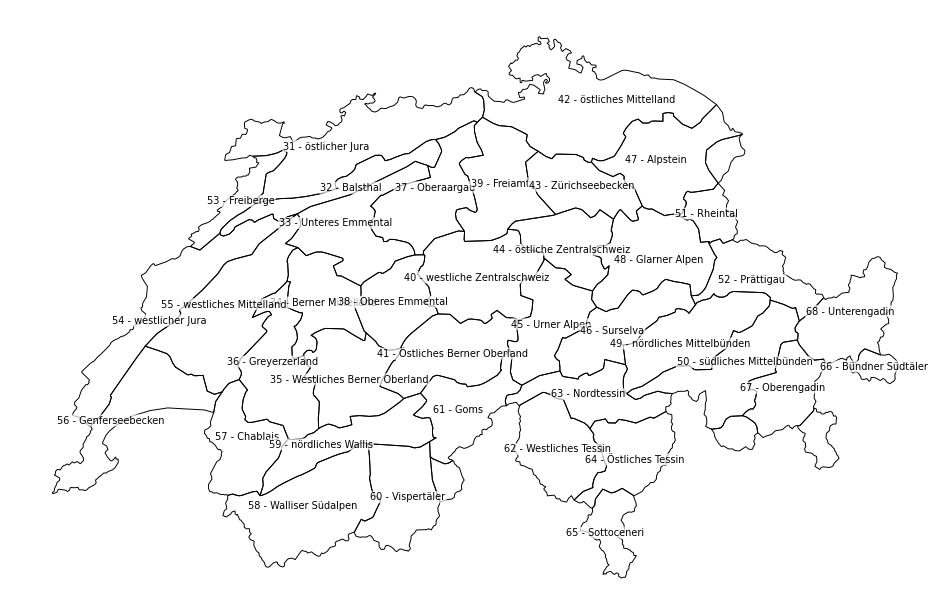

In [57]:
plot_region_polygon()

In [58]:
RID_PLATEAU = [55,33,37,32,39,43,42]

RID_ALPS = [57,59,58,60,61,63,45,46,49,50,67]

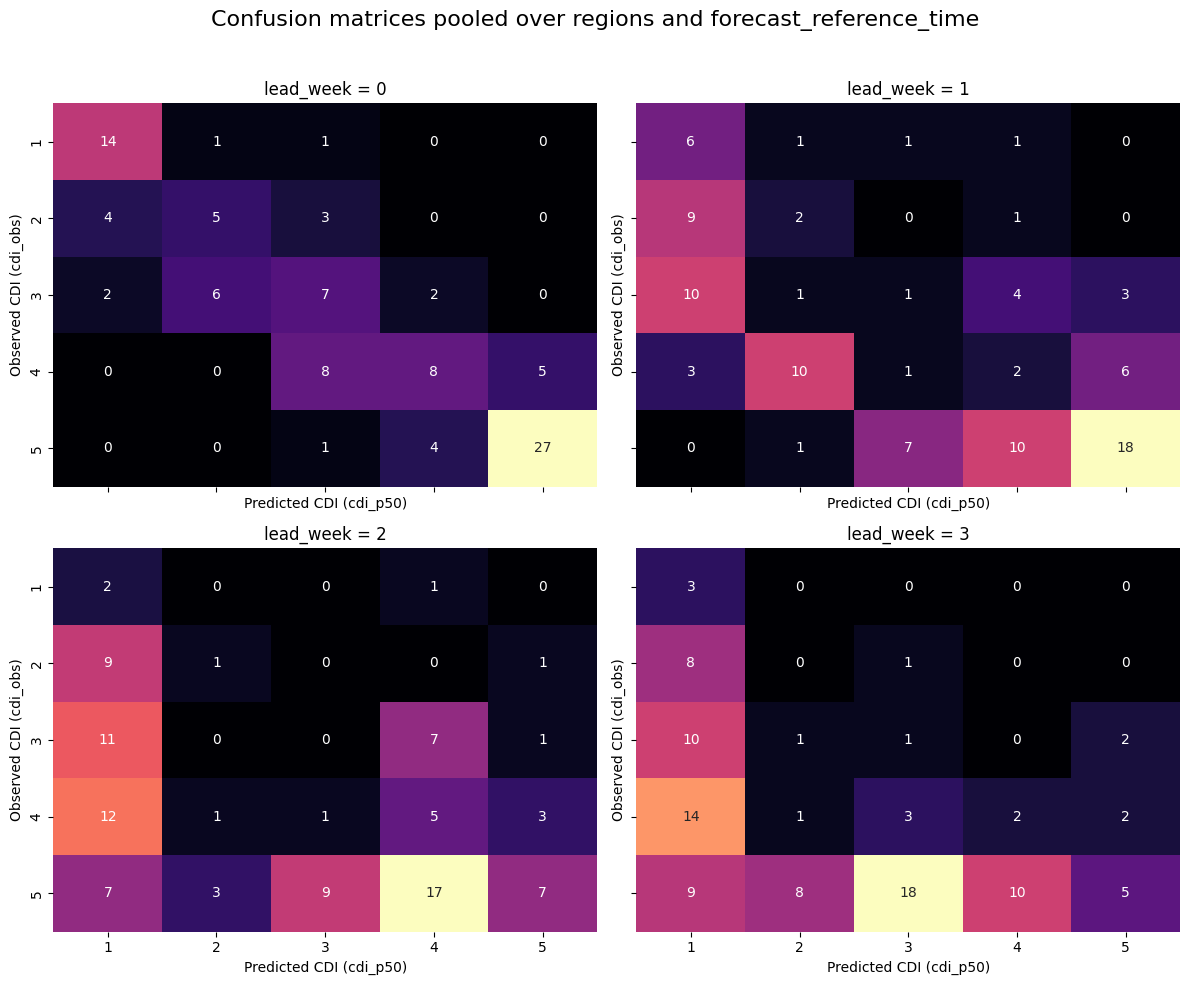

In [59]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# ds is your xarray dataset
# set `var` to choose variable (base name), e.g. "cdi", "precip_sum_1m", "soil_moisture_ufc"
var = "cdi"
obs = f"{var}_obs"
p50 = f"{var}_p50"
df = ds_mondays[[obs, p50]].sel(forecast_reference_time=slice("2026-04-01",None)).sel(drought_region_id=RID_PLATEAU).to_dataframe().reset_index()

# if your CDI classes are 1..5
levels = np.arange(1, 6)

fig, axes = plt.subplots(2, 2, figsize=(12, 10), sharex=True, sharey=True)

for ax, lead in zip(axes.ravel(), sorted(df["lead_week"].unique())):
    subset = df[df["lead_week"] == lead]
    y_true = subset[obs].astype(int)
    y_pred = subset[p50].astype(int)

    cm = confusion_matrix(y_true, y_pred, labels=levels)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="magma",
        xticklabels=levels,
        yticklabels=levels,
        cbar=False,
        ax=ax,
    )
    ax.set_title(f"lead_week = {lead}")
    ax.set_xlabel(f"Predicted {var.upper()} ({p50})")
    ax.set_ylabel(f"Observed {var.upper()} ({obs})")

fig.suptitle("Confusion matrices pooled over regions and forecast_reference_time", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

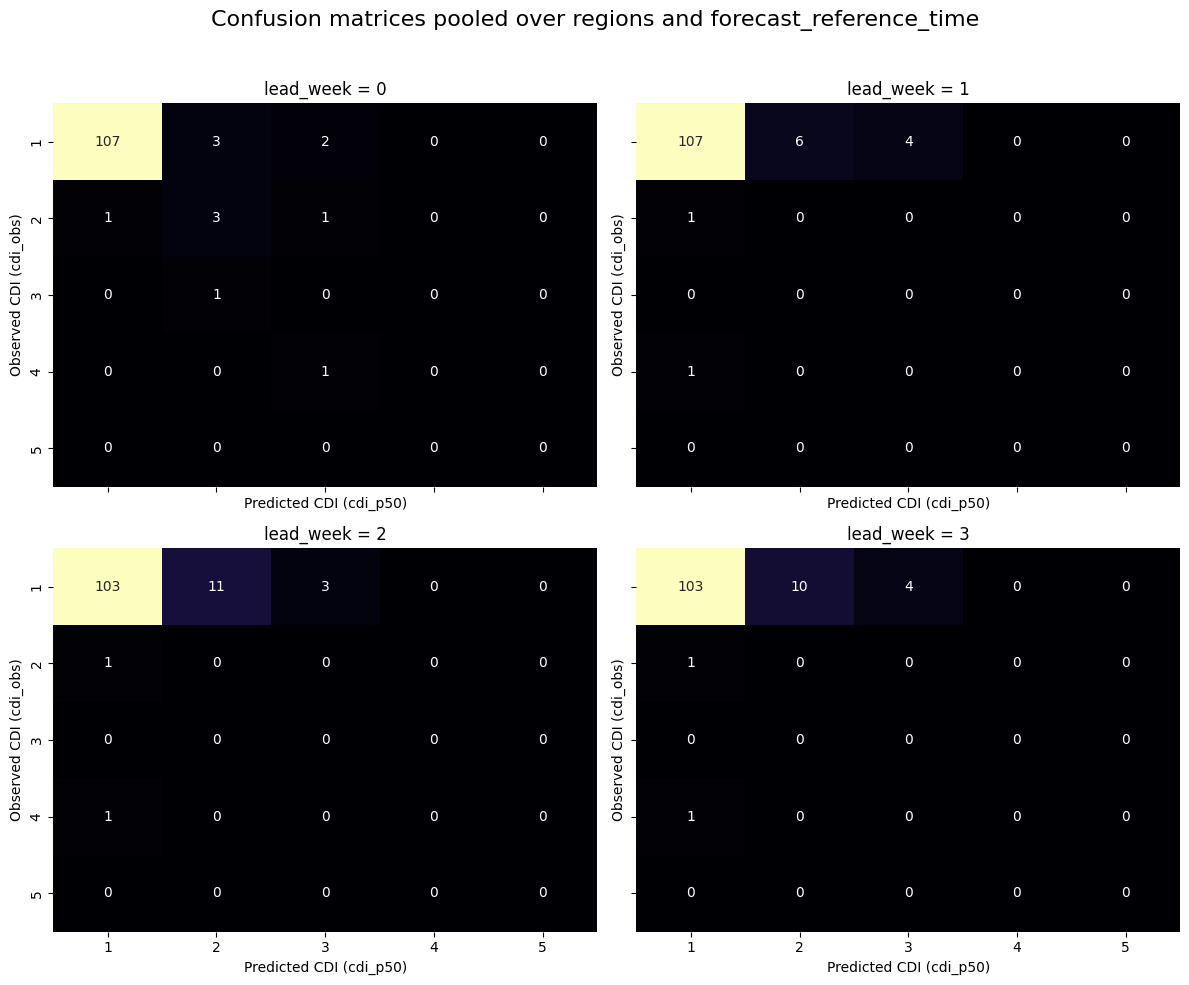

In [60]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# ds is your xarray dataset
# set `var` to choose variable (base name), e.g. "cdi", "precip_sum_1m", "soil_moisture_ufc"
var = "cdi"
obs = f"{var}_obs"
p50 = f"{var}_p50"
df = ds_mondays[[obs, p50]].sel(forecast_reference_time=slice("2025-07-01","2025-10-31")).sel(drought_region_id=RID_PLATEAU).to_dataframe().reset_index()

# if your CDI classes are 1..5
levels = np.arange(1, 6)

fig, axes = plt.subplots(2, 2, figsize=(12, 10), sharex=True, sharey=True)

for ax, lead in zip(axes.ravel(), sorted(df["lead_week"].unique())):
    subset = df[df["lead_week"] == lead]
    y_true = subset[obs].astype(int)
    y_pred = subset[p50].astype(int)

    cm = confusion_matrix(y_true, y_pred, labels=levels)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="magma",
        xticklabels=levels,
        yticklabels=levels,
        cbar=False,
        ax=ax,
    )
    ax.set_title(f"lead_week = {lead}")
    ax.set_xlabel(f"Predicted {var.upper()} ({p50})")
    ax.set_ylabel(f"Observed {var.upper()} ({obs})")

fig.suptitle("Confusion matrices pooled over regions and forecast_reference_time", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

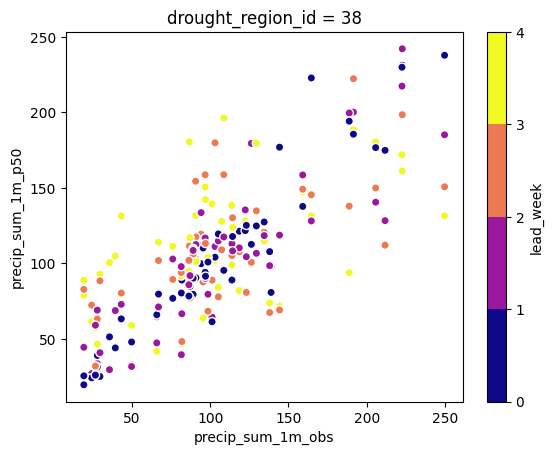

In [ ]:
ds_mondays[[ "precip_sum_1m_obs", "precip_sum_1m_p50" ]].sel(drought_region_id=38).plot.scatter(x="precip_sum_1m_obs", y="precip_sum_1m_p50", levels=range(5), hue="lead_week",cmap="plasma")

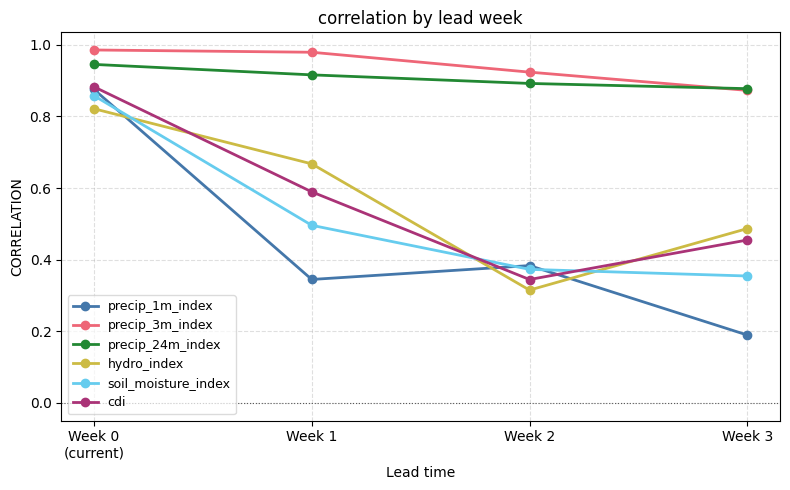

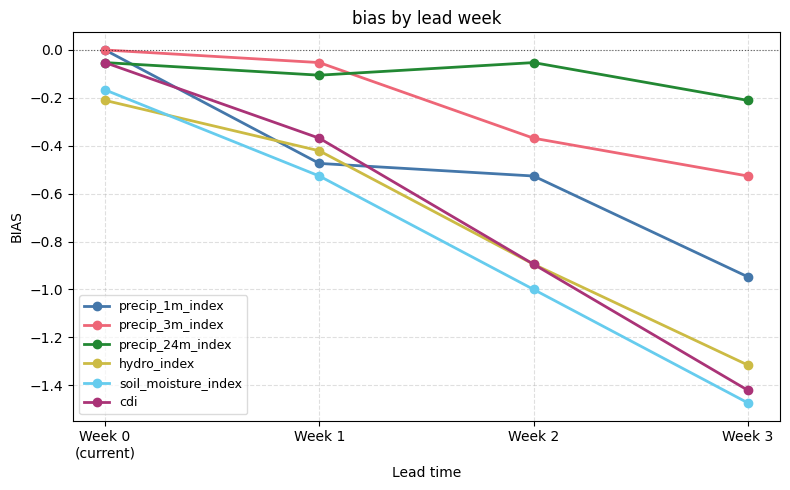

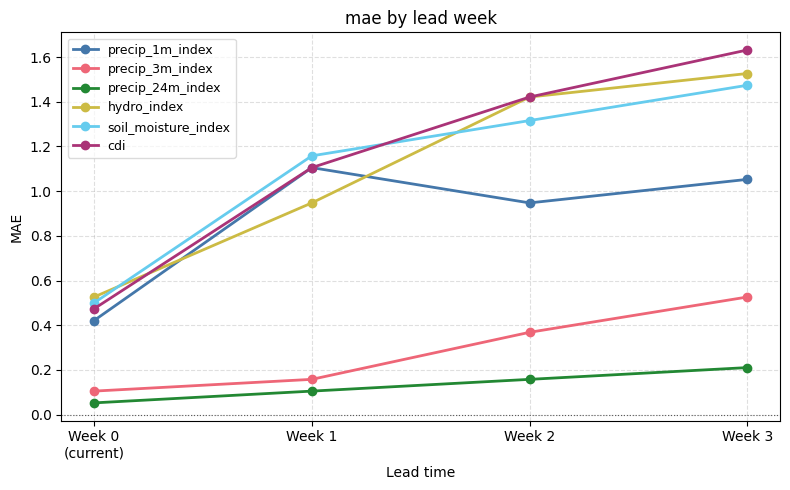

In [63]:
for _score in ["correlation","bias","mae"]:
    fig = plot_skill_vs_lead(
        ds_scores.sel(drought_region_id=42),
        variables=["precip_1m_index", "precip_3m_index", "precip_24m_index", "hydro_index", "soil_moisture_index", "cdi"],
        aggregate_regions=True,
        score=f"{_score}",
        title=f"{_score} by lead week",
    )
    plt.show()

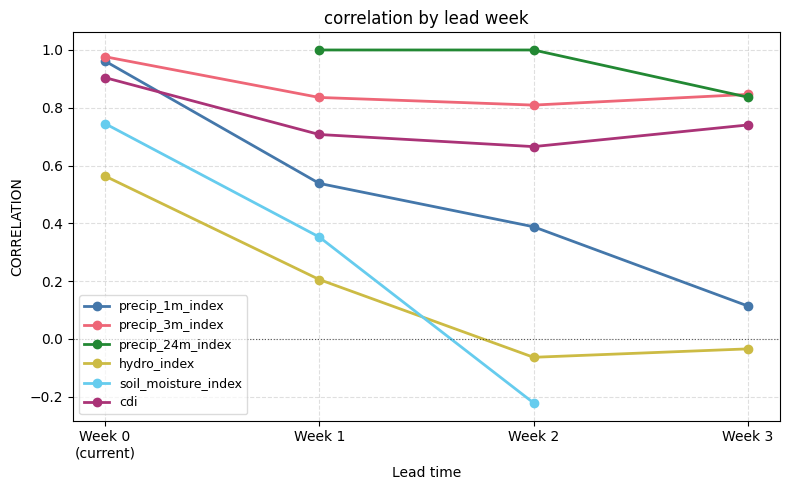

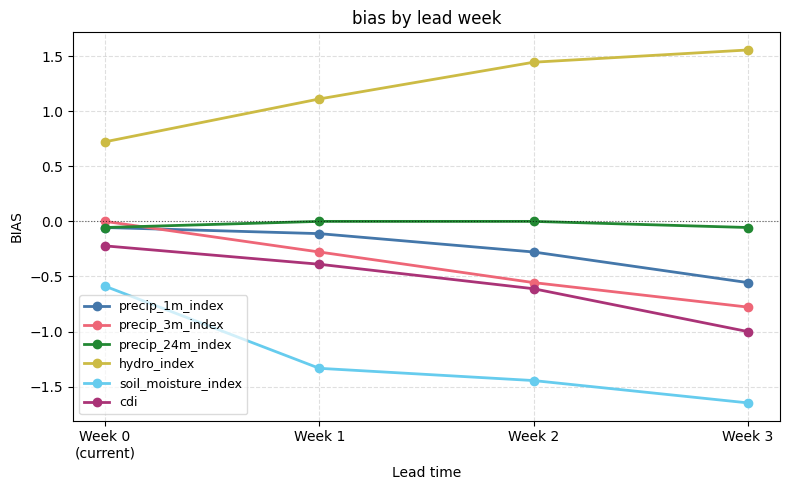

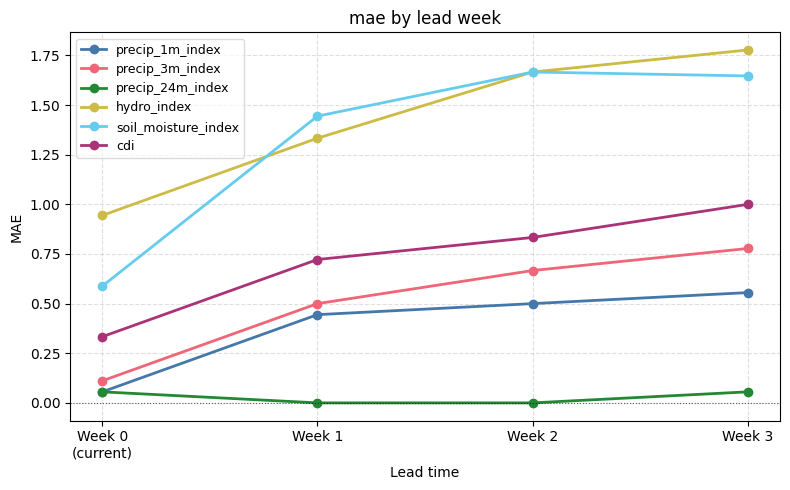

In [ ]:
for _score in ["correlation","bias","mae"]:
    fig = plot_skill_vs_lead(
        ds_scores.sel(drought_region_id=60),
        variables=["precip_1m_index", "precip_3m_index", "precip_24m_index", "hydro_index", "soil_moisture_index", "cdi"],
        aggregate_regions=True,
        score=f"{_score}",
        title=f"{_score} by lead week",
    )
    plt.show()

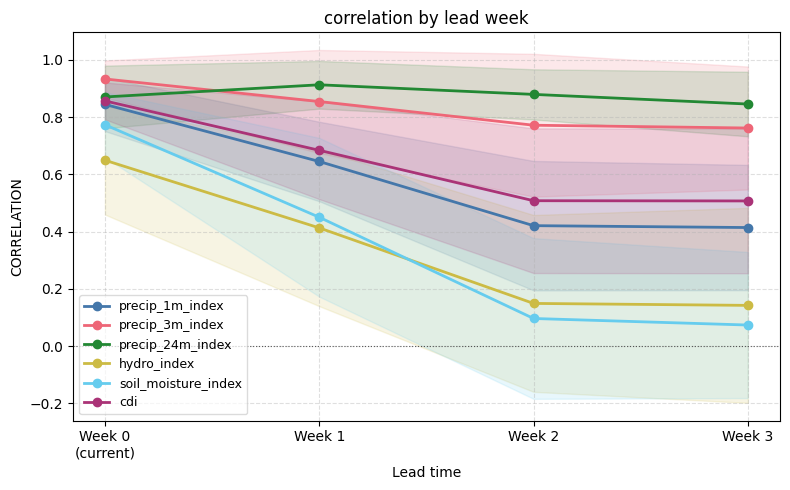

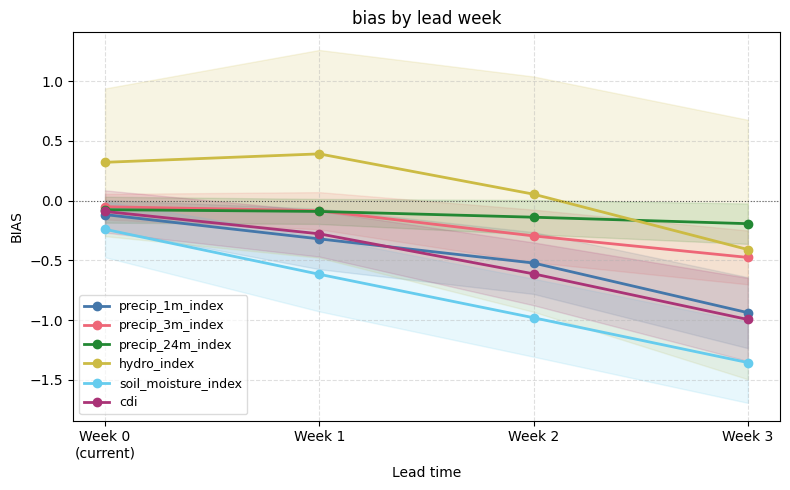

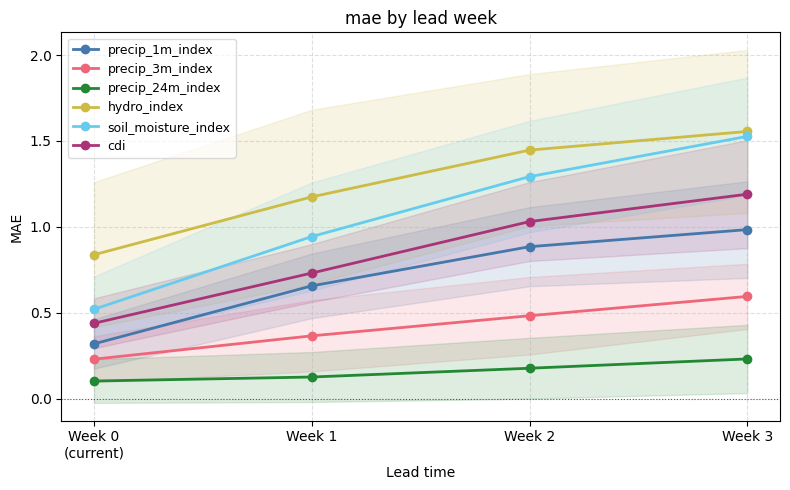

In [ ]:
for _score in ["correlation","bias","mae"]:
    fig = plot_skill_vs_lead(
        ds_scores, #.sel(drought_region_id=60),
        variables=["precip_1m_index", "precip_3m_index", "precip_24m_index", "hydro_index", "soil_moisture_index", "cdi"],
        aggregate_regions=True,
        score=f"{_score}",
        title=f"{_score} by lead week",
    )
    plt.show()

In [69]:
ds_scores

<xarray.Dataset> Size: 110kB
Dimensions:                           (drought_region_id: 38, lead_week: 4)
Coordinates:
  * drought_region_id                 (drought_region_id) int64 304B 31 ... 68
  * lead_week                         (lead_week) int64 32B 0 1 2 3
Data variables: (12/90)
    cdi_mae                           (drought_region_id, lead_week) float64 1kB ...
    cdi_rmse                          (drought_region_id, lead_week) float64 1kB ...
    cdi_bias                          (drought_region_id, lead_week) float64 1kB ...
    cdi_correlation                   (drought_region_id, lead_week) float64 1kB ...
    precip_1m_index_mae               (drought_region_id, lead_week) float64 1kB ...
    precip_1m_index_rmse              (drought_region_id, lead_week) float64 1kB ...
    ...                                ...
    soil_moisture_ufc_mae             (drought_region_id, lead_week) float64 1kB ...
    soil_moisture_ufc_rmse            (drought_region_id, lead_week) float64 1kB ...
    soil_moisture_ufc_bias            (drought_region_id, lead_week) float64 1kB ...
    soil_moisture_ufc_correlation     (drought_region_id, lead_week) float64 1kB ...
    soil_moisture_ufc_pinball         (drought_region_id, lead_week) float64 1kB ...
    soil_moisture_ufc_interval_score  (drought_region_id, lead_week) float64 1kB ...
Attributes:
    source:            drought_forecast_eval
    variables_scored:  cdi,precip_1m_index,precip_3m_index,precip_24m_index,h...
    scores_computed:   mae,rmse,bias,correlation,pinball,interval_score
    cdi_threshold:     2
    reference_type:    climatology

/home/ima/work/projects/drought-forecast-eval/drought_forecast_eval/visualization/region_map.py:212: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  for panel_idx, lw in enumerate(lead_weeks):
/home/ima/work/projects/drought-forecast-eval/drought_forecast_eval/visualization/region_map.py:212: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  for panel_idx, lw in enumerate(lead_weeks):
/home/ima/work/projects/drought-forecast-eval/drought_forecast_eval/visualization/region_map.py:212: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  for panel_idx, lw in enumerate(lead_weeks):
/home/ima/work/projects/drought-forecast-eval/drought_forecast_eval/visualization/region_map.py:212: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  for 

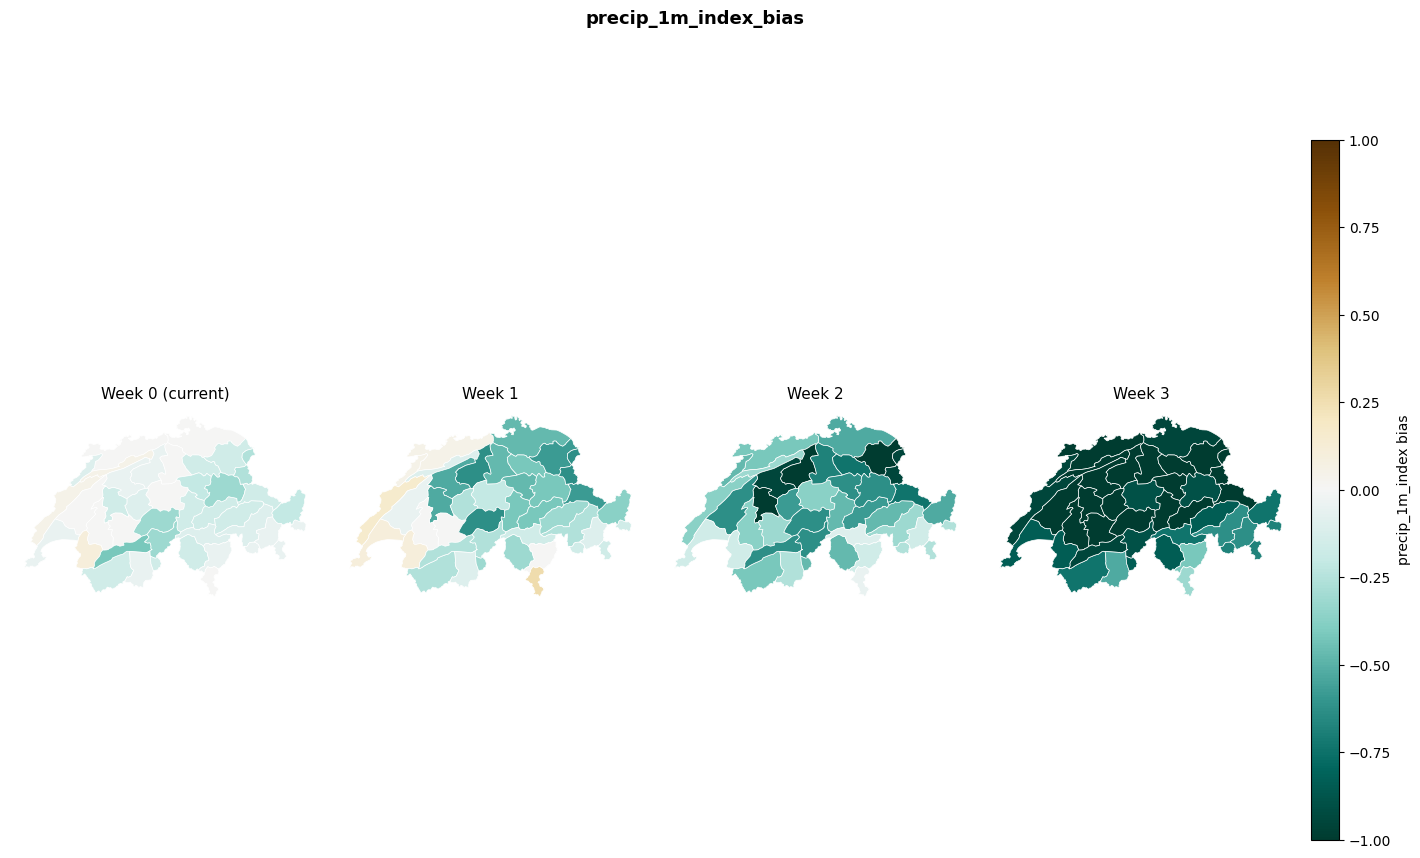

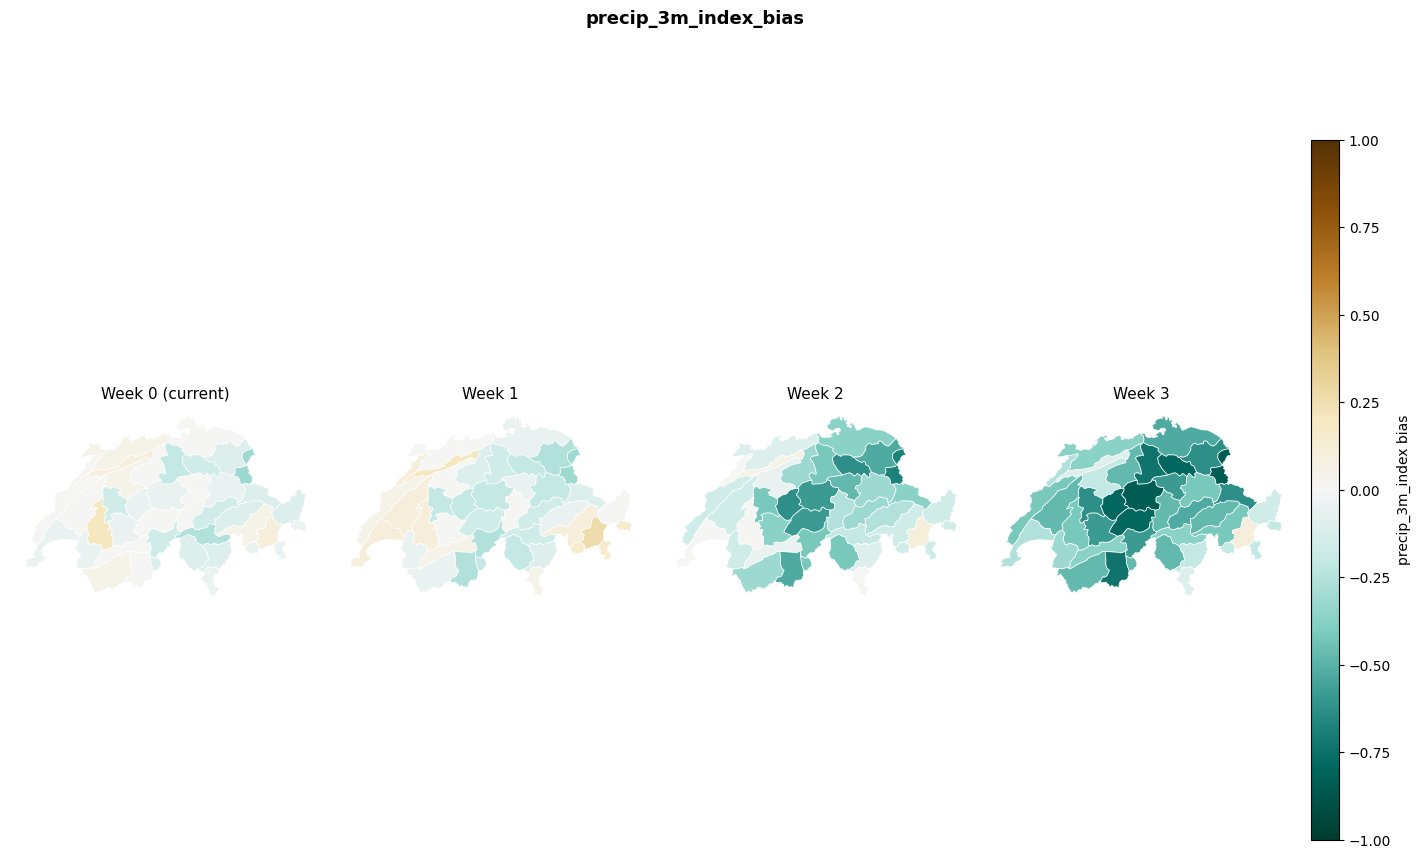

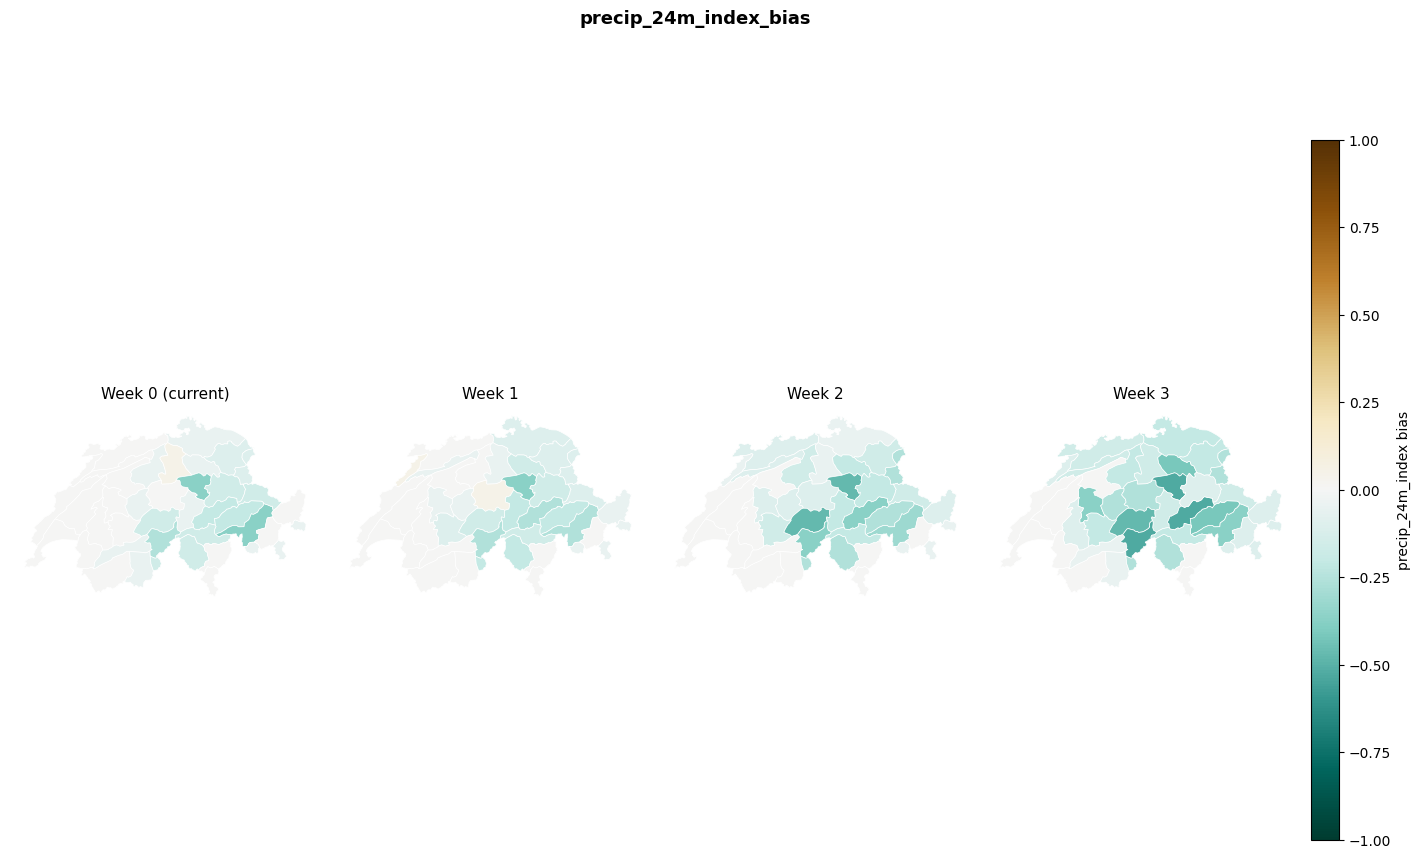

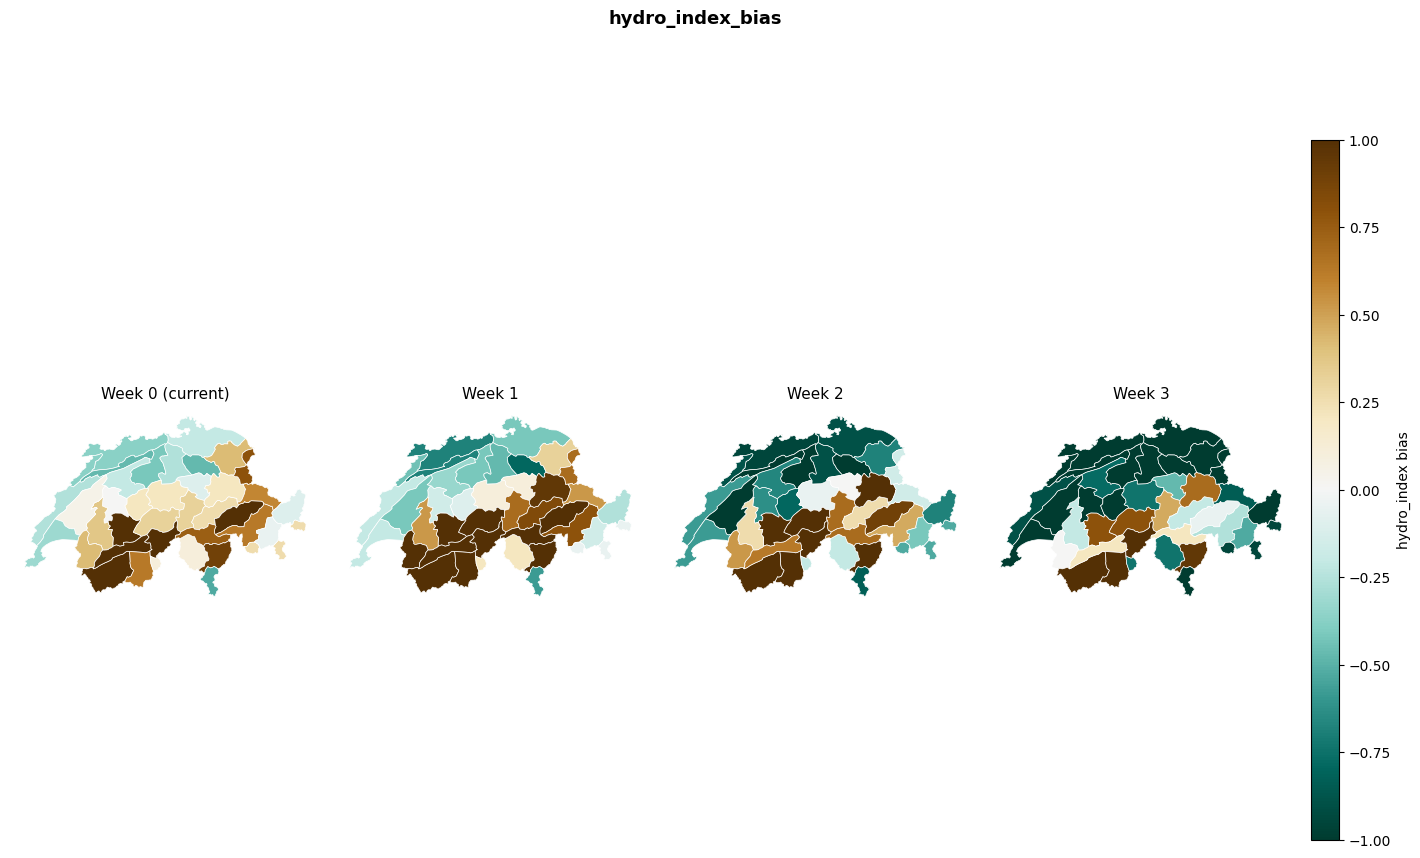

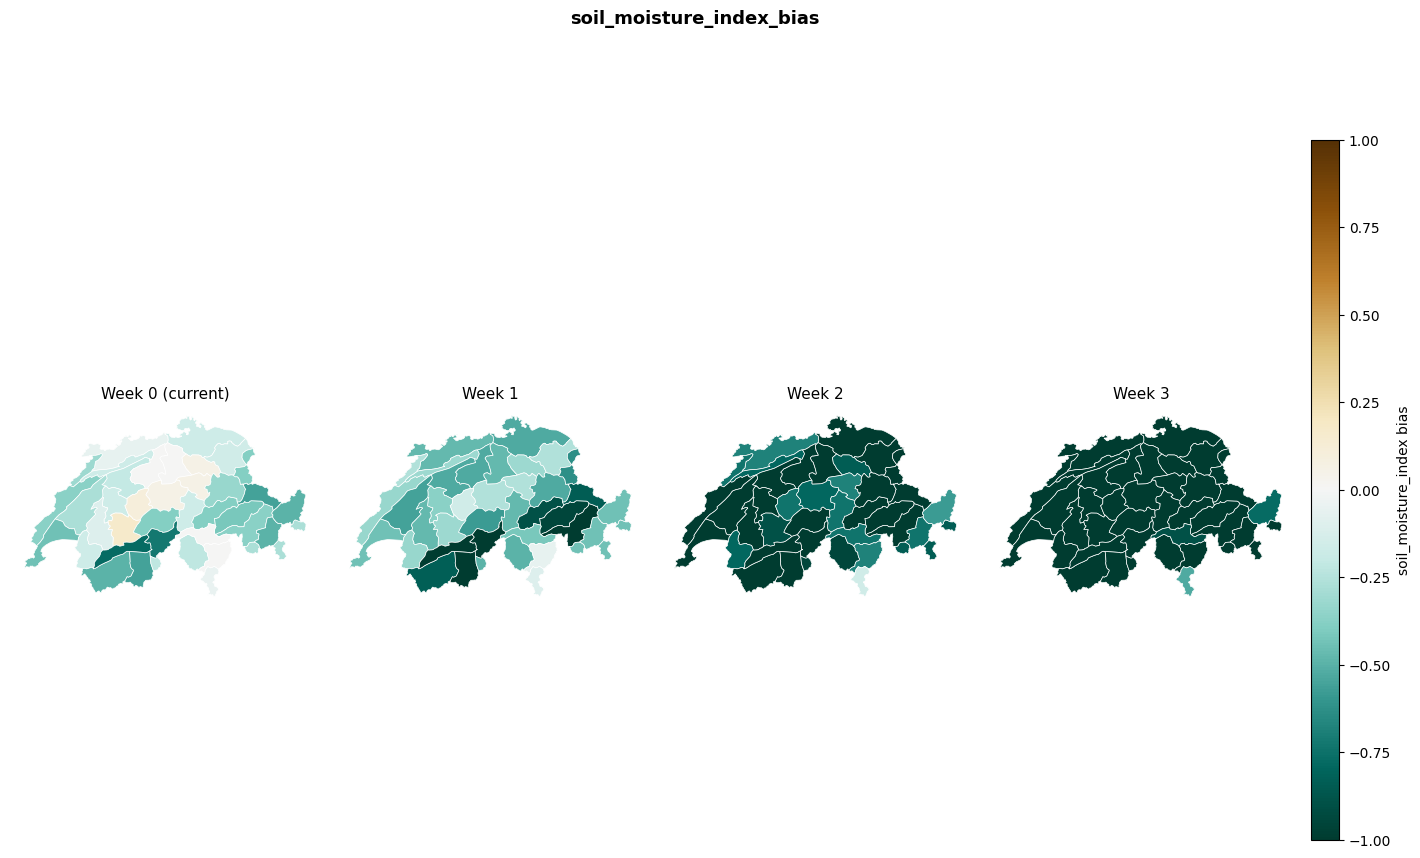

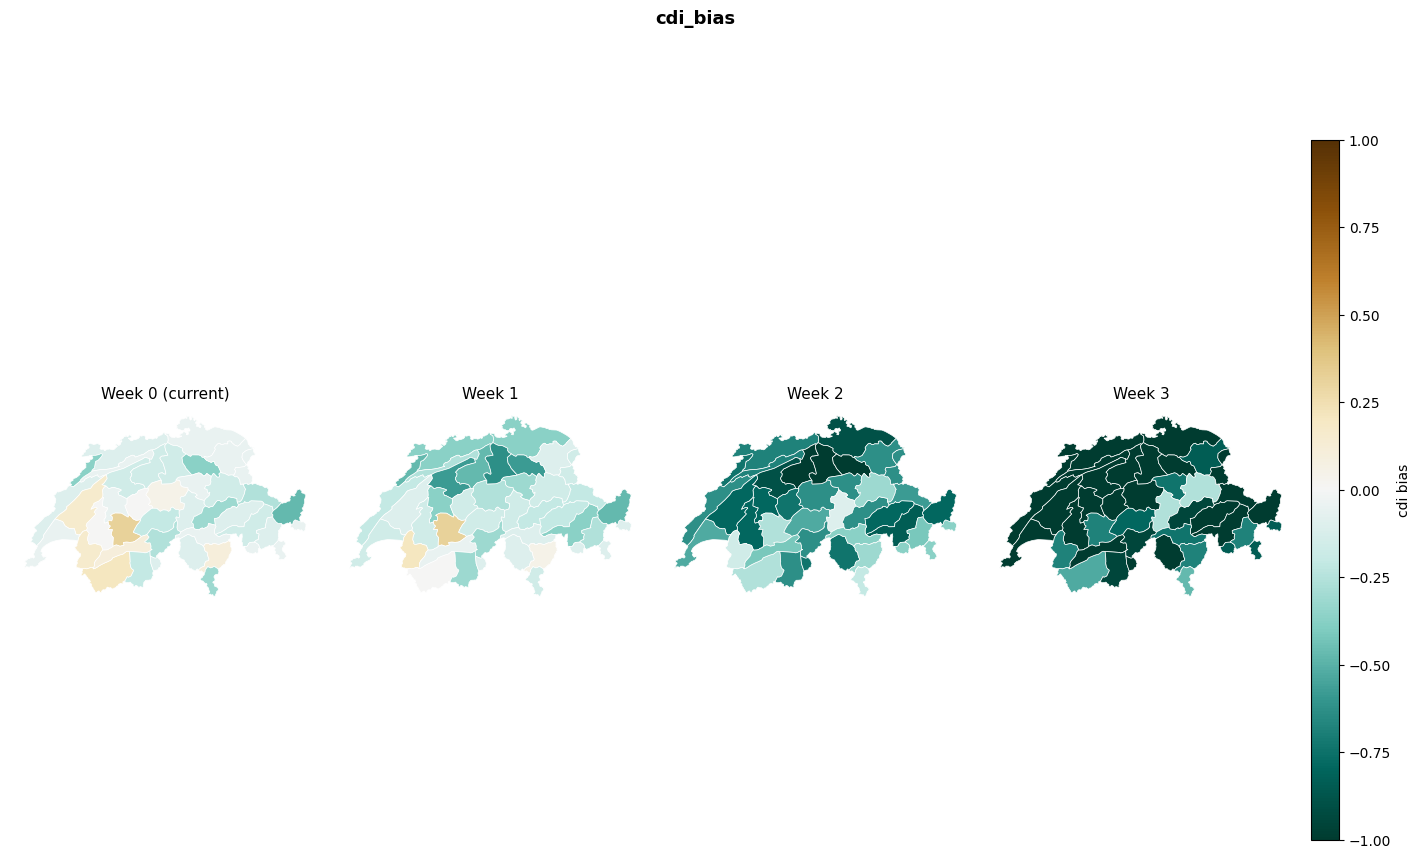

In [77]:
# Regional map (requires shapefile; falls back to bar chart if not provided)
from drought_forecast_eval.visualization import plot_region_map


score = "bias"

fig3 = plot_region_map(
    ds_scores=ds_scores,
    score_variable=f"precip_1m_index_{score}",
    shapefile_path=SHAPEFILE,
    lead_weeks=[0, 1, 2, 3],
    cmap="BrBG_r",
    vmin=-1,
    vmax=1
)
fig3 = plot_region_map(
    ds_scores=ds_scores,
    score_variable=f"precip_3m_index_{score}",
    shapefile_path=SHAPEFILE,
    lead_weeks=[0, 1, 2, 3],
    cmap="BrBG_r",
    vmin=-1,
    vmax=1
)
fig3 = plot_region_map(
    ds_scores=ds_scores,
    score_variable=f"precip_24m_index_{score}",
    shapefile_path=SHAPEFILE,
    lead_weeks=[0, 1, 2, 3],
    cmap="BrBG_r",
    vmin=-1,
    vmax=1
)
fig4 = plot_region_map(
    ds_scores=ds_scores,
    score_variable=f"hydro_index_{score}",
    shapefile_path=SHAPEFILE,
    lead_weeks=[0, 1, 2, 3],
    cmap="BrBG_r",
    vmin=-1,
    vmax=1
)
fig4 = plot_region_map(
    ds_scores=ds_scores,
    score_variable=f"soil_moisture_index_{score}",
    shapefile_path=SHAPEFILE,
    lead_weeks=[0, 1, 2, 3],
    cmap="BrBG_r",
    vmin=-1,
    vmax=1
)

fig4 = plot_region_map(
    ds_scores=ds_scores,
    score_variable=f"cdi_{score}",
    shapefile_path=SHAPEFILE,
    lead_weeks=[0, 1, 2, 3],
    cmap="BrBG_r",
    vmin=-1,
    vmax=1
)


plt.show()

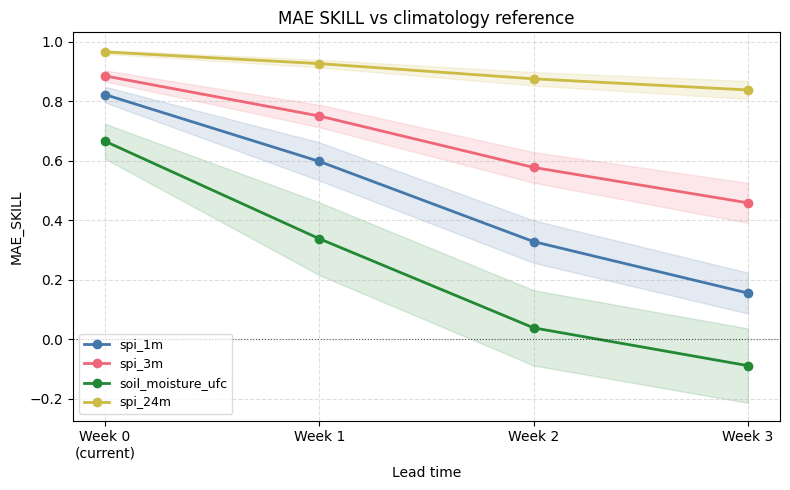

In [ ]:
# RPSS (requires reference forecast)
ds_scores_w_skill = compute_scores(
    ds_merged,
    variables=["spi_1m", "spi_3m", "spi_24m", "soil_moisture_ufc", "hydro_index"],
    scores=["mae_skill"],
    ds_ref=ds_ref_clim,
)

fig2 = plot_skill_vs_lead(
    ds_scores_w_skill,
    variables=["spi_1m", "spi_3m","soil_moisture_ufc","spi_24m"],
    score="mae_skill",
    zero_line=True,
    title="MAE SKILL vs climatology reference",
)
plt.show()

In [ ]:
ds_merged

<xarray.Dataset> Size: 25MB
Dimensions:                  (forecast_reference_time: 351,
                              drought_region_id: 38, lead_week: 4)
Coordinates:
  * forecast_reference_time  (forecast_reference_time) datetime64[us] 3kB 202...
  * drought_region_id        (drought_region_id) int64 304B 31 32 33 ... 67 68
  * lead_week                (lead_week) int64 32B 0 1 2 3
    valid_at                 (forecast_reference_time, drought_region_id, lead_week) datetime64[ns] 427kB ...
Data variables: (12/57)
    cdi_p50                  (forecast_reference_time, drought_region_id, lead_week) float64 427kB ...
    precip_1m_index_p50      (forecast_reference_time, drought_region_id, lead_week) float64 427kB ...
    precip_3m_index_p50      (forecast_reference_time, drought_region_id, lead_week) float64 427kB ...
    precip_24m_index_p50     (forecast_reference_time, drought_region_id, lead_week) float64 427kB ...
    hydro_index_p50          (forecast_reference_time, drought_region_id, lead_week) float64 427kB ...
    soil_moisture_index_p50  (forecast_reference_time, drought_region_id, lead_week) float64 427kB ...
    ...                       ...
    spi_3m_obs               (forecast_reference_time, drought_region_id, lead_week) float64 427kB ...
    spi_6m_obs               (forecast_reference_time, drought_region_id, lead_week) float64 427kB ...
    spi_12m_obs              (forecast_reference_time, drought_region_id, lead_week) float64 427kB ...
    spi_24m_obs              (forecast_reference_time, drought_region_id, lead_week) float64 427kB ...
    soil_moisture_ufc_obs    (forecast_reference_time, drought_region_id, lead_week) float64 427kB ...
    vhi_obs                  (forecast_reference_time, drought_region_id, lead_week) float64 427kB ...
Attributes:
    source:       drought_forecast_eval
    description:  Swiss drought forecast archive

/home/ima/work/projects/drought-forecast-eval/drought_forecast_eval/visualization/region_map.py:212: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 0.94, 1])
/home/ima/work/projects/drought-forecast-eval/drought_forecast_eval/visualization/region_map.py:212: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 0.94, 1])
/home/ima/work/projects/drought-forecast-eval/drought_forecast_eval/visualization/region_map.py:212: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 0.94, 1])


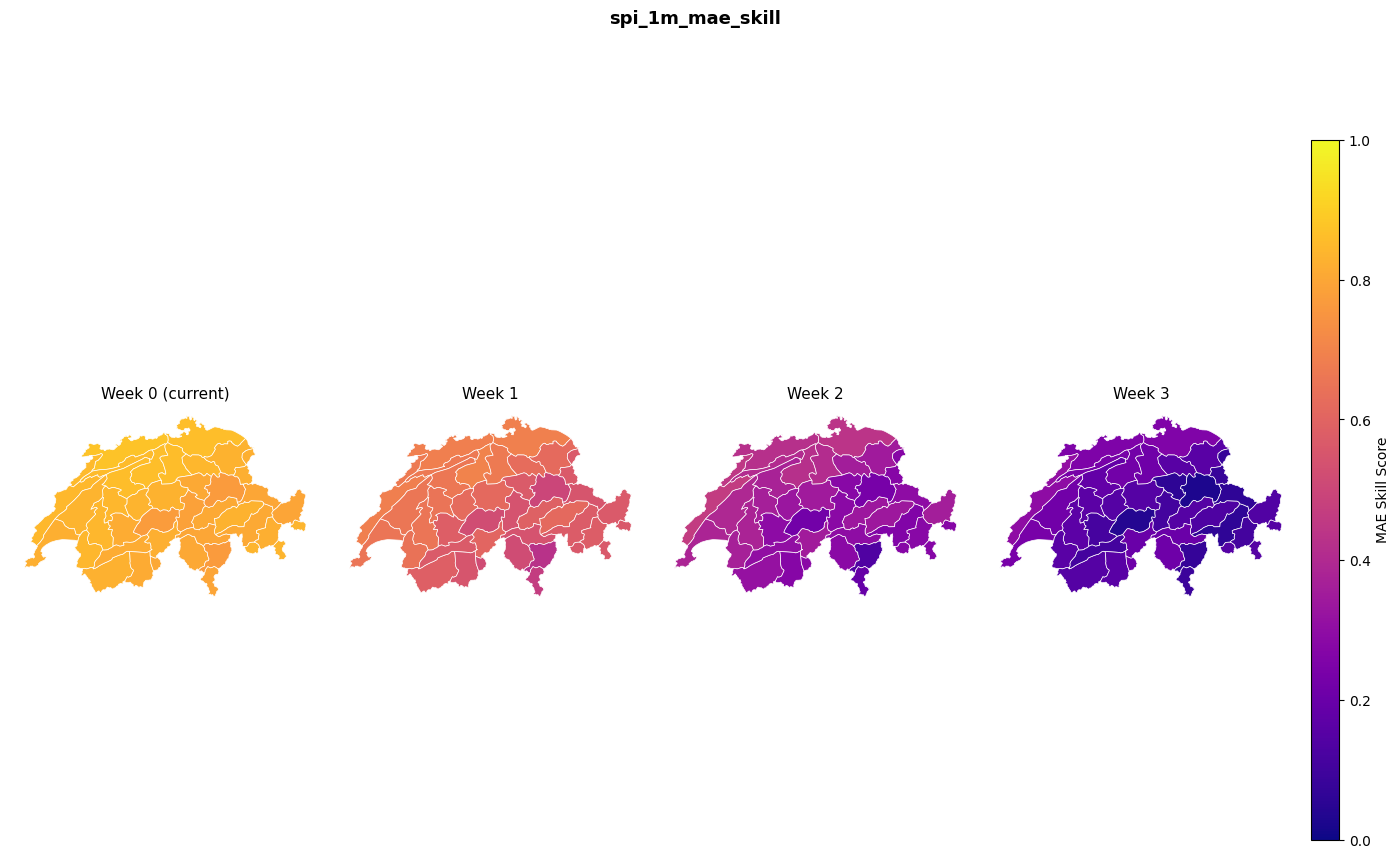

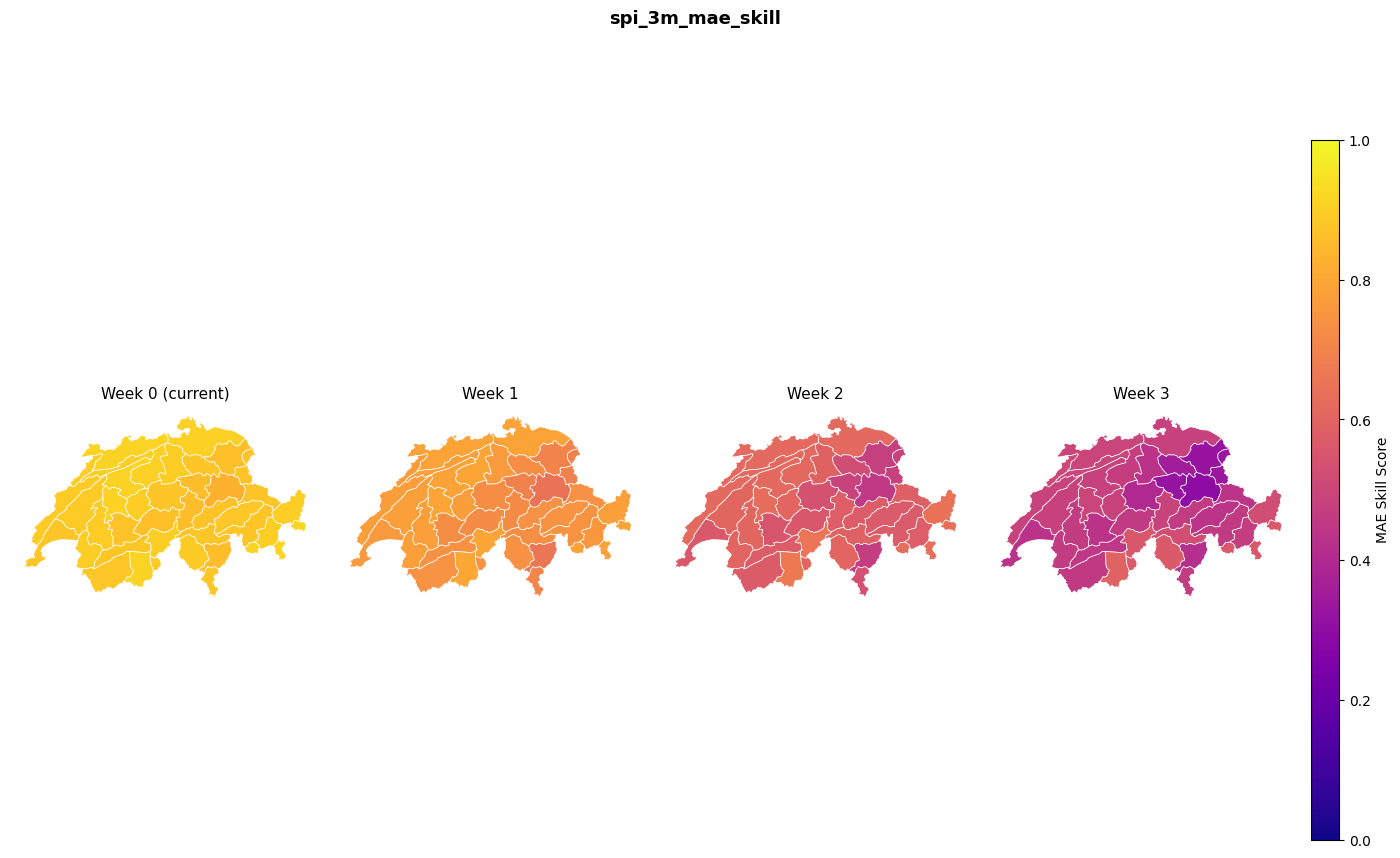

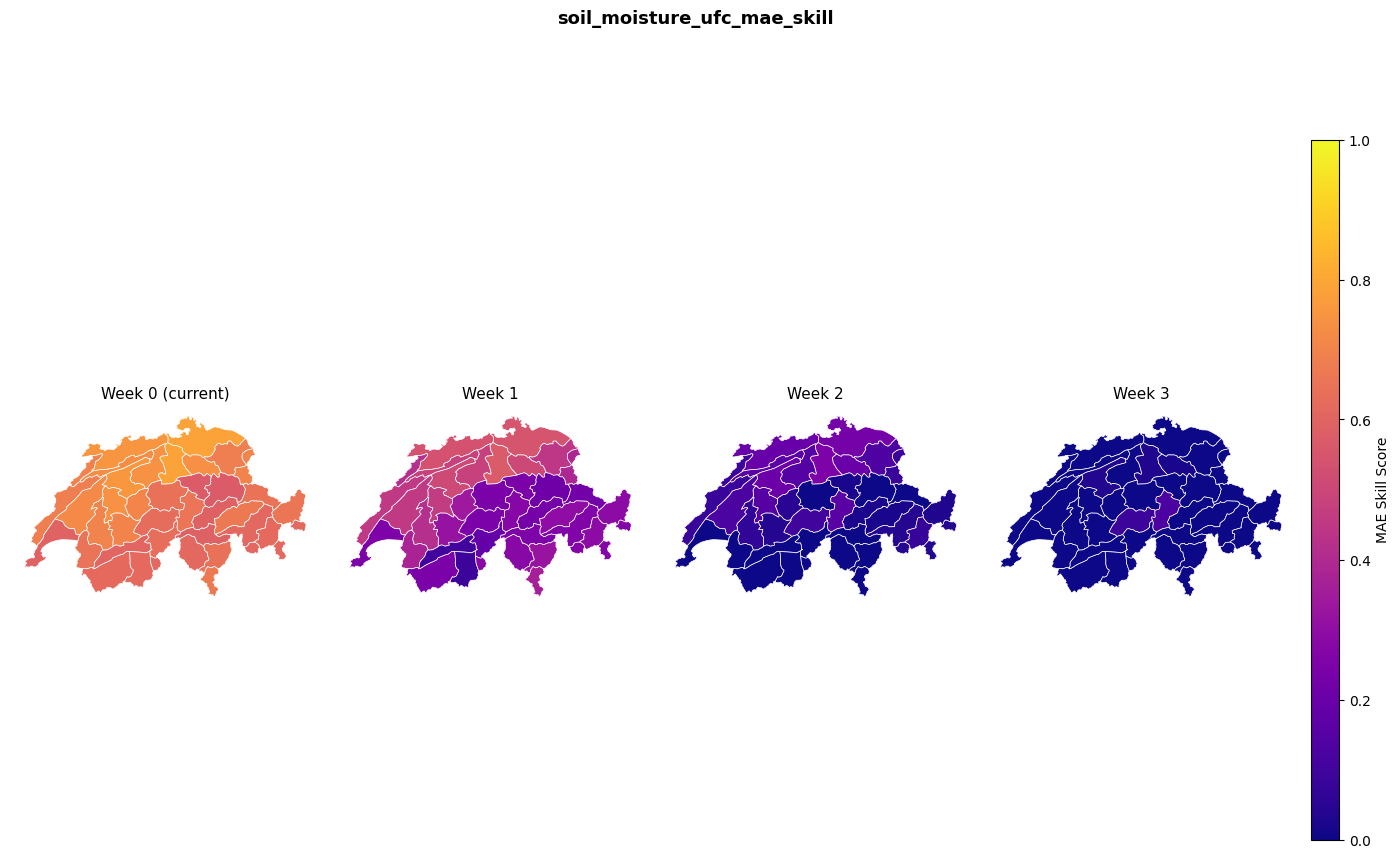

In [ ]:
# Regional map (requires shapefile; falls back to bar chart if not provided)
from drought_forecast_eval.visualization import plot_region_map

fig3 = plot_region_map(
    ds_scores_w_skill,
    score_variable="spi_1m_mae_skill",
    shapefile_path=SHAPEFILE,
    lead_weeks=[0, 1, 2, 3],
    cmap="plasma",
    vmin=0,
    vmax=1
)
fig3 = plot_region_map(
    ds_scores_w_skill,
    score_variable="spi_3m_mae_skill",
    shapefile_path=SHAPEFILE,
    lead_weeks=[0, 1, 2, 3],
    cmap="plasma",
    vmin=0,
    vmax=1
)
fig3 = plot_region_map(
    ds_scores_w_skill,
    score_variable="soil_moisture_ufc_mae_skill",
    shapefile_path=SHAPEFILE,
    lead_weeks=[0, 1, 2, 3],
    cmap="plasma",
    vmin=0,
    vmax=1
)


plt.show()

trockenheitsdaten-numerisch_current.csv.202509192100.zip: filename date (2025-09-19) differs from header date (2025-09-18); using filename date.
trockenheitsdaten-numerisch_current.csv.202606212100.zip: filename date (2026-06-21) differs from header date (2026-06-20); using filename date.
trockenheitsdaten-numerisch_current.csv.202607202100.zip: filename date (2026-07-20) differs from header date (2026-07-19); using filename date.
Coverage for 'cdi_obs': 21888 / 28880 cells (75.8%)
Coverage for 'precip_1m_index_obs': 21888 / 28880 cells (75.8%)
Coverage for 'precip_3m_index_obs': 21888 / 28880 cells (75.8%)
Coverage for 'precip_24m_index_obs': 21888 / 28880 cells (75.8%)
Coverage for 'hydro_index_obs': 21888 / 28880 cells (75.8%)
Coverage for 'soil_moisture_index_obs': 21888 / 28880 cells (75.8%)
Coverage for 'precip_sum_1m_obs': 21888 / 28880 cells (75.8%)
Coverage for 'precip_sum_3m_obs': 21888 / 28880 cells (75.8%)
Coverage for 'precip_sum_6m_obs': 21888 / 28880 cells (75.8%)
Covera

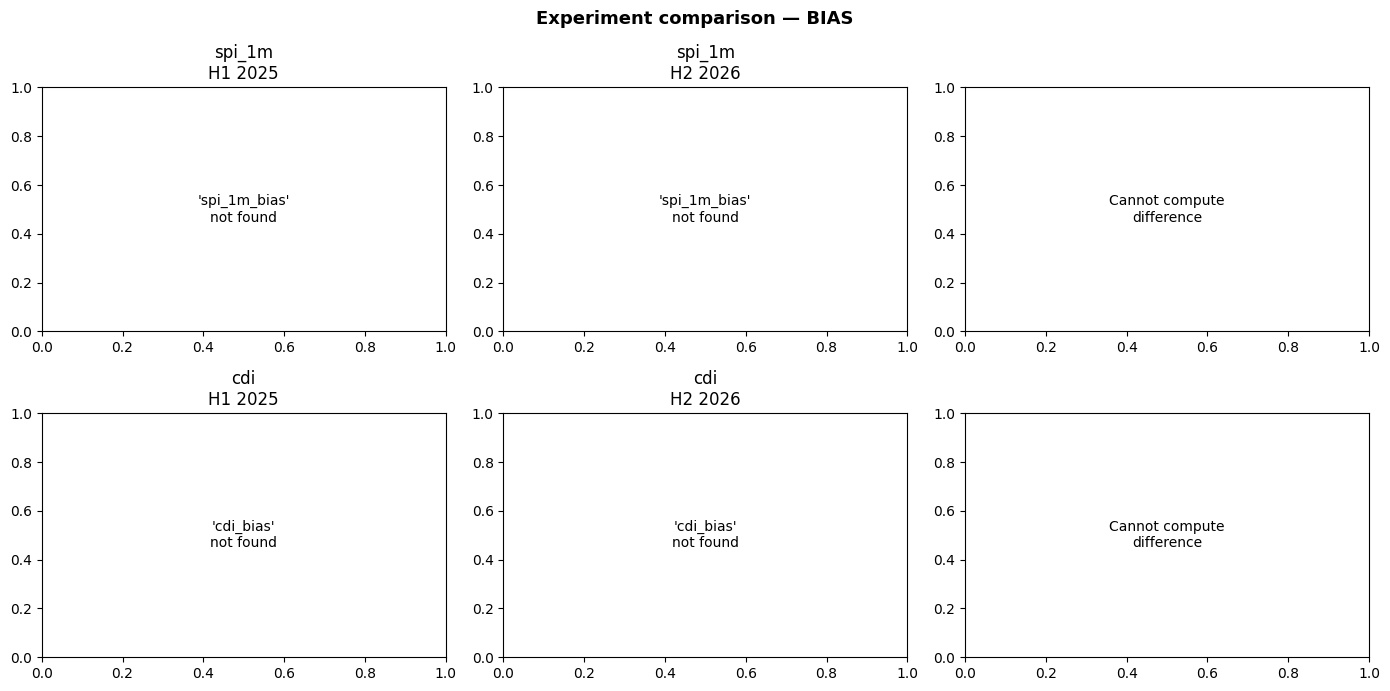

In [ ]:
# Experiment comparison: period A vs period B
from drought_forecast_eval.visualization import plot_experiment_diff

# Example: compare first half vs second half of the year
DATE_RANGE_A = ("2025-07-01", "2025-10-29")
DATE_RANGE_B = ("2026-03-01", "2026-07-30")

ds_fcst_a = load_forecasts(ARCHIVE_DIR, date_range=DATE_RANGE_A, region_ids=region_ids)
ds_fcst_b = load_forecasts(ARCHIVE_DIR, date_range=DATE_RANGE_B, region_ids=region_ids)

ds_merged_a = align_obs_to_forecast(ds_fcst_a, ds_obs)
ds_merged_b = align_obs_to_forecast(ds_fcst_b, ds_obs)

ds_ref_a = climatology_reference(ds_obs, ds_fcst_a)
ds_ref_b = climatology_reference(ds_obs, ds_fcst_b)

ds_scores_a = compute_scores(ds_merged_a, variables=["spi_1m", "cdi"], scores=["mae"], ds_ref=ds_ref_a)
ds_scores_b = compute_scores(ds_merged_b, variables=["spi_1m", "cdi"], scores=["mae"], ds_ref=ds_ref_b)

fig4 = plot_experiment_diff(
    ds_scores_a, ds_scores_b,
    variables=["spi_1m", "cdi"],
    score="bias",
    label_a="H1 2025",
    label_b="H2 2026",
)
plt.show()

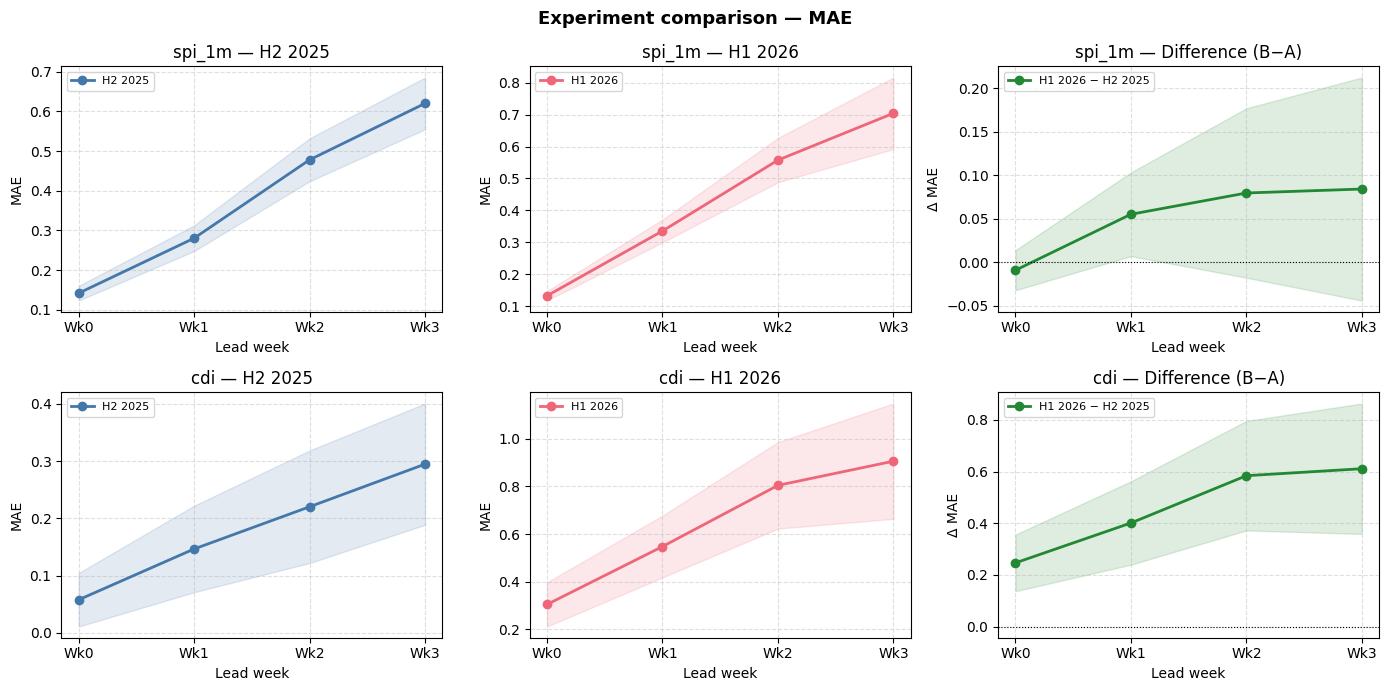

In [ ]:
fig4 = plot_experiment_diff(
    ds_scores_a, ds_scores_b,
    variables=["spi_1m", "cdi"],
    score="mae",
    label_a="H2 2025",
    label_b="H1 2026",
)
plt.show()

## 7. Export results

In [ ]:
from drought_forecast_eval import ReportBuilder

builder = ReportBuilder(
    archive_dir=ARCHIVE_DIR,
    historic_path=HISTORIC_ZIP,
    date_range=DATE_RANGE,
    regions=REGIONS,
    variables=VARIABLES,
    scores="default",
    reference="climatology",
    cdi_threshold=CDI_THRESHOLD,
    shapefile_path=SHAPEFILE,
    output_dir=OUTPUT_DIR,
)

# Run the full pipeline and write all outputs
outputs = builder.run()
print("Outputs:")
for key, path in outputs.items():
    print(f"  {key}: {path}")

trockenheitsdaten-numerisch_current.csv.202509192100.zip: filename date (2025-09-19) differs from header date (2025-09-18); using filename date.
trockenheitsdaten-numerisch_current.csv.202511042100.zip: filename date (2025-11-04) differs from header date (2025-11-03); using filename date.
trockenheitsdaten-numerisch_current.csv.202601082100.zip: filename date (2026-01-08) differs from header date (2026-01-07); using filename date.
Coverage for 'cdi_obs': 25308 / 53352 cells (47.4%)
Coverage for 'precip_1m_index_obs': 25308 / 53352 cells (47.4%)
Coverage for 'precip_3m_index_obs': 25308 / 53352 cells (47.4%)
Coverage for 'precip_24m_index_obs': 25308 / 53352 cells (47.4%)
Coverage for 'hydro_index_obs': 25308 / 53352 cells (47.4%)
Coverage for 'soil_moisture_index_obs': 25308 / 53352 cells (47.4%)
Coverage for 'precip_sum_1m_obs': 25308 / 53352 cells (47.4%)
Coverage for 'precip_sum_3m_obs': 25308 / 53352 cells (47.4%)
Coverage for 'precip_sum_6m_obs': 25308 / 53352 cells (47.4%)
Covera

Outputs:
  netcdf: ../output/scores_20250705_20260620.nc
  csv: ../output/scores_summary.csv
  html: ../output/report.html


In [ ]:
# Or export individually:
# builder.export_netcdf(OUTPUT_DIR / "scores.nc")
# builder.export_csv(OUTPUT_DIR / "scores_summary.csv")
# builder.export_html(OUTPUT_DIR / "report.html")